# Universities Ranking Analysis

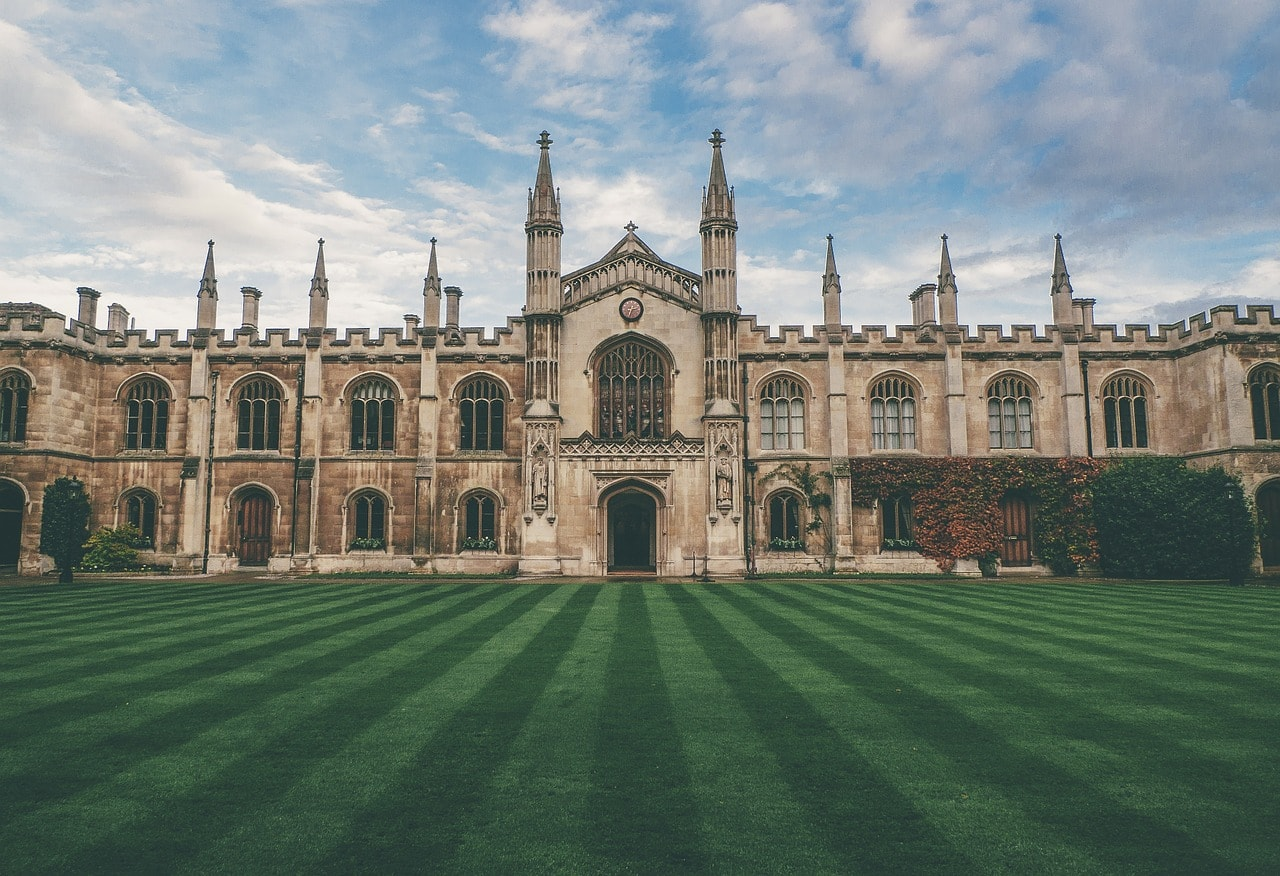

## 🎓 What Makes a World-Class University?
### A statistical data-analysis study of the CWUR 2018–19 World University Rankings

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">Dataset</b></p>
<p><b>Universities Information Dataset</b> – my own Kaggle dataset of the CWUR 2018–19 world university ranking: <b>1,000 institutions from 61 countries</b>, each with its world rank, country, national rank, a final <b>score (0–100)</b> and <b>seven rank-based indicators</b> (quality of education, alumni employment, quality of faculty, research output, quality publications, influence and citations). The ranking methodology and original data are © CWUR.</p>
<p>The file hides two traps: missing values are written as the string <code>"-"</code> (education: 597 of 1,000 rows, faculty: 731) and ranks beyond the cut-off as <code>"&gt; 1000"</code> (for example 509 values for alumni employment). Both are examined and handled explicitly in the audit.</p>
<p style="margin-bottom:0"><b>Source:</b> Kaggle dataset <code>universities-information-dataset</code> · <b>Stack:</b> Python, pandas, SciPy, statsmodels, scikit-learn, seaborn · <b>Runtime:</b> CPU only, ≈ 1–2 minutes</p>
</div>

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">Contents</b></p>
<ul style="margin-bottom:0">
<li><a href="#lenses" style="color:#c27849; font-weight:600">Two Lenses: Data Analysis Meets Data Science</a></li>
<li><a href="#questions" style="color:#c27849; font-weight:600">The Questions Behind the Ranks</a></li>
<li><a href="#setup" style="color:#c27849; font-weight:600">Setting the Stage: Tools and Data</a></li>
<li><a href="#audit" style="color:#c27849; font-weight:600">What the Ranking Hides: Audit and Cleaning</a></li>
<li><a href="#univariate" style="color:#c27849; font-weight:600">One Variable at a Time</a></li>
<li><a href="#geography" style="color:#c27849; font-weight:600">Where Excellence Lives: Geography and Concentration</a></li>
<li><a href="#relationships" style="color:#c27849; font-weight:600">How the Indicators Move Together</a></li>
<li><a href="#leakage" style="color:#c27849; font-weight:600">Rank vs. Score: A Leakage Warning</a></li>
<li><a href="#inference" style="color:#c27849; font-weight:600">Are the Differences Real? Statistical Inference</a></li>
<li><a href="#regression" style="color:#c27849; font-weight:600">Explaining the Score: Regression and Diagnostics</a></li>
<li><a href="#structure" style="color:#c27849; font-weight:600">The Hidden Structure of Excellence: PCA and Clustering</a></li>
<li><a href="#standouts" style="color:#c27849; font-weight:600">Who Stands Out? Reputation vs. Research</a></li>
<li><a href="#conclusions" style="color:#c27849; font-weight:600">What We Found: Conclusions, Limits and Next Steps</a></li>
</ul>
</div>

<a class="anchor" id="lenses"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">Two Lenses: Data Analysis Meets Data Science</p>

| Layer | Question it answers | Where in this notebook |
|---|---|---|
| **Data analysis** (descriptive → inferential) | *What happened and is it real?* – distributions, country concentration, hypothesis tests, effect sizes, uncertainty | *One Variable at a Time* → *Are the Differences Real? Statistical Inference* |
| **Data science** (modelling *for understanding*) | *What structure and drivers sit behind the numbers?* – regression diagnostics, PCA, clustering, residual analysis. Models are used as analytical tools; **there is no prediction or train/test machine learning** | *Explaining the Score: Regression and Diagnostics* → *Who Stands Out? Reputation vs. Research* |
| **Where they overlap** | Regression, PCA and effect sizes are both *inference* and *data science*; cleaning decisions (censoring, circularity of the score) shape every test and model | *What the Ranking Hides: Audit and Cleaning*, *Are the Differences Real? Statistical Inference*, *Explaining the Score: Regression and Diagnostics* |

<a class="anchor" id="questions"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">The Questions Behind the Ranks</p>

1. **Structure** – How are the ranking indicators distributed, and how strongly are they related?
2. **Geography** – Is university quality concentrated in a few countries/continents, and are the differences *statistically* and *practically* significant?
3. **Probability** – For a given country, what is the probability that an institution reaches the Top 100 (with uncertainty)?
4. **Drivers** – Which indicators carry the most information about the final score?
5. **Hidden structure** – Do the indicators reduce to a few dimensions or natural groups?
6. **Standouts** – Which universities have an employment reputation far above (or below) what their research profile implies?

<a class="anchor" id="setup"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">Setting the Stage: Tools and Data</p>

**Reproducibility rules used throughout:** a single global random seed, every figure saved to `figures/`, no hidden state between sections, and every analytical decision justified in the text.

In [1]:
import os, re, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

SEED = 42
rng = np.random.default_rng(SEED)
ALPHA = 0.05
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

def md(text):            # render markdown generated from computed results
    display(Markdown(text))

def save(fig, name):     # consistent figure export for the README / portfolio
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"))

def stars(p):
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"

In [2]:
import glob
FILE_NAME = "eighteen_nineteen_university_datasets.csv"
CANDIDATES = [
    f"/kaggle/input/universities-information-dataset/{FILE_NAME}",   # Kaggle (expected slug)
    f"data/{FILE_NAME}", FILE_NAME,                                   # local / GitHub clone
]
# robust discovery: if the Kaggle slug differs, search every attached input for the file (or any CSV with a "World Rank" header)
for pattern in (f"/kaggle/input/**/{FILE_NAME}", "/kaggle/input/**/*.csv", "data/*.csv", "*.csv"):
    CANDIDATES += sorted(glob.glob(pattern, recursive=True))
def _looks_right(p):
    try:
        return "World Rank" in pd.read_csv(p, nrows=1, encoding="cp1252").columns.str.replace(r"\s+", " ", regex=True).str.strip()
    except Exception:
        return False
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p) and _looks_right(p)), None)
assert DATA_PATH, "Dataset not found – on Kaggle click 'Add Input' and attach the dataset; locally put the CSV in ./data/"
print("Using file:", DATA_PATH)

# The file is Windows-1252 encoded (the non-breaking space 0xA0 in headers broke utf-8 in the first version).
# `unicode_escape` "worked" before but silently mangles non-ASCII institution names; cp1252 is the correct codec.
for enc in ("utf-8", "cp1252", "latin-1"):
    try:
        raw = pd.read_csv(DATA_PATH, encoding=enc)
        print(f"Loaded with encoding = {enc!r}  ->  {raw.shape[0]:,} rows × {raw.shape[1]} columns")
        break
    except UnicodeDecodeError:
        continue

# normalise whitespace in headers and text columns (removes \xa0)
clean_ws = lambda s: re.sub(r"\s+", " ", str(s)).strip()
raw.columns = [clean_ws(c) for c in raw.columns]
for c in raw.columns:
    if pd.api.types.is_string_dtype(raw[c]) or raw[c].dtype == object:
        raw[c] = raw[c].map(clean_ws)

RENAME = {
    "World Rank": "world_rank", "Institution": "institution", "Location": "country",
    "National Rank": "national_rank", "Quality of Education": "edu", "Alumni Employment": "alumni",
    "Quality of Faculty": "faculty", "Research Output": "research_output",
    "Quality Publications": "quality_pubs", "Influence": "influence", "Citations": "citations", "Score": "score",
}
raw = raw.rename(columns=RENAME)
raw.head()

Using file: /kaggle/input/universities-information-dataset/eighteen_nineteen_university_datasets.csv
Loaded with encoding = 'cp1252'  ->  1,000 rows × 12 columns


,world_rank,institution,country,national_rank,edu,alumni,faculty,research_output,quality_pubs,influence,citations,score
0,1,Harvard University,USA,1,2,1,1,1,1,1,1,100.000
1,2,Stanford University,USA,2,10,3,2,10,4,3,2,96.700
2,3,Massachusetts Institute of Technology,USA,3,3,11,3,30,15,2,6,95.100
3,4,University of Cambridge,United Kingdom,1,5,19,6,12,8,6,19,94.000
4,5,University of Oxford,United Kingdom,2,9,25,10,9,5,7,4,93.200


<a class="anchor" id="audit"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">What the Ranking Hides: Audit and Cleaning</p>

### What does each column mean?
CWUR ranks universities on **seven indicators**. Every indicator column is itself a **rank** (1 = best), *not* a score – so **lower is better**, and the final `score` is a weighted aggregate of them.

| Column | Meaning |
|---|---|
| `world_rank`, `national_rank` | Overall rank (derived from `score`) / rank inside the country |
| `edu`, `alumni` | Quality of education (alumni awards) / alumni employment (CEO-level positions) |
| `faculty` | Quality of faculty (staff awards) |
| `research_output`, `quality_pubs`, `influence`, `citations` | Publication volume, top-tier-journal publications, influential-journal publications, highly-cited papers |
| `score` | Final CWUR score (0–100) |

### Look for *hidden* missing values
`df.isnull().sum()` reported **zero** nulls in the original notebook – but that is misleading: missing data is encoded as the **string `"-"`** and rank values beyond the cut-off as **`"> 1000"`**. Both silently turned the columns into `object` dtype.

In [3]:
def placeholder_report(frame):
    rows = {}
    for c in frame.columns:
        s = frame[c].astype(str).str.strip()
        rows[c] = {"dtype": str(frame[c].dtype), "n_unique": frame[c].nunique(),
                   "true NaN": int(frame[c].isna().sum()),
                   'placeholder "-"': int((s == "-").sum()),
                   'censored "> 1000"': int(s.str.startswith(">").sum())}
    return pd.DataFrame(rows).T

display(placeholder_report(raw))
print("Duplicated institutions:", raw.institution.duplicated().sum(), "| fully duplicated rows:", raw.duplicated().sum())

,dtype,n_unique,true NaN,"placeholder ""-""","censored ""> 1000"""
world_rank,int64,1000,0,0,0
institution,object,1000,0,0,0
country,object,61,0,0,0
national_rank,int64,213,0,0,0
edu,object,404,0,597,0
alumni,object,492,0,0,509
faculty,object,221,0,731,0
research_output,object,905,0,0,77
quality_pubs,object,892,0,0,51
influence,object,830,0,0,171


Duplicated institutions: 0 | fully duplicated rows: 0


### Decisions (and why)

| Problem | Naïve fix (original notebook) | Decision here | Rationale |
|---|---|---|---|
| `"-"` in `edu` / `faculty` | Drop both columns | Convert to `NaN`, **keep the columns**, analyse the missingness pattern | Dropping discards information; whether data is missing *at random* is itself a finding |
| `"> 1000"` in rank indicators | Replace with `1001` and treat as a normal value | Store `1001` **plus a boolean `*_censored` flag**; run sensitivity checks that exclude censored rows | These are *right-censored* ranks (“worse than 1000”). Treating them as exact values biases correlations |
| Rank direction | Used raw ranks (lower = better) | Add **`*_str` “strength” columns** = `1001 − rank` (higher = better) | Positive correlations then mean “better ⇒ better”, which makes plots and coefficients readable |
| `unicode_escape` encoding | – | `cp1252` + whitespace normalisation | Correct codec, no mangled names |
| Country labels | Raw strings | Add **continent** mapping | Needed for tests with adequate group sizes |

In [4]:
IND = ["edu", "alumni", "faculty", "research_output", "quality_pubs", "influence", "citations"]
IND_LABEL = {"edu": "Quality of Education", "alumni": "Alumni Employment", "faculty": "Quality of Faculty",
             "research_output": "Research Output", "quality_pubs": "Quality Publications",
             "influence": "Influence", "citations": "Citations"}
CORE = ["alumni", "research_output", "quality_pubs", "influence", "citations"]   # fully observed indicators
RESEARCH = ["research_output", "quality_pubs", "influence", "citations"]
CENSOR_VALUE = 1001

df = raw.copy()
for c in IND:
    s = df[c].astype(str).str.strip()
    df[f"{c}_censored"] = s.str.startswith(">")
    num = pd.to_numeric(s.str.replace(r"^>\s*", "", regex=True).replace({"-": np.nan}), errors="coerce")
    num[df[f"{c}_censored"]] = CENSOR_VALUE
    df[c] = num
    df[f"{c}_str"] = CENSOR_VALUE - df[c]          # strength: higher = better

for c in ["world_rank", "national_rank"]:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")
df["score"] = pd.to_numeric(df["score"], errors="coerce")

# --- continent mapping --------------------------------------------------------------------------------
CONTINENT = {}
for cont, ctrs in {
    "North America": ["USA", "Canada", "Mexico", "Puerto Rico", "Cuba"],
    "South America": ["Brazil", "Argentina", "Chile", "Colombia", "Uruguay", "Venezuela", "Peru", "Ecuador"],
    "Europe": ["United Kingdom", "Germany", "France", "Italy", "Spain", "Netherlands", "Switzerland", "Sweden", "Russia",
               "Poland", "Finland", "Belgium", "Austria", "Denmark", "Norway", "Portugal", "Greece", "Czech Republic",
               "Ireland", "Hungary", "Serbia", "Slovenia", "Croatia", "Lithuania", "Estonia", "Slovak Republic",
               "Slovakia", "Romania", "Bulgaria", "Ukraine", "Cyprus", "Iceland", "Luxembourg", "Turkey"],
    "Asia": ["China", "Japan", "South Korea", "Taiwan", "India", "Iran", "Israel", "Hong Kong", "Singapore", "Saudi Arabia",
             "Malaysia", "Thailand", "Lebanon", "Pakistan", "Jordan", "United Arab Emirates", "Qatar", "Kuwait", "Oman",
             "Bangladesh", "Sri Lanka", "Indonesia", "Vietnam", "Philippines", "Kazakhstan", "Iraq", "Macau"],
    "Africa": ["Egypt", "South Africa", "Nigeria", "Ghana", "Kenya", "Uganda", "Tunisia", "Morocco", "Ethiopia", "Algeria"],
    "Oceania": ["Australia", "New Zealand"],
}.items():
    CONTINENT.update({c: cont for c in ctrs})
df["continent"] = df["country"].map(CONTINENT).fillna("Other")
print("Unmapped countries (add them to CONTINENT if any):", sorted(df.loc[df.continent == "Other", "country"].unique()))

# --- derived features -----------------------------------------------------------------------------------
df["tier"] = pd.cut(df["world_rank"].astype(float), [0, 100, 500, np.inf], labels=["Top 100", "101–500", "501–1000"])
df["top100"] = (df["world_rank"] <= 100).astype(int)
df["log_score"] = np.log(df["score"])

TIER_ORDER = ["Top 100", "101–500", "501–1000"]
TIER_PAL = dict(zip(TIER_ORDER, ["#1b9e77", "#7570b3", "#d95f02"]))
print(f"\nClean frame: {df.shape[0]:,} rows × {df.shape[1]} columns")
df[["world_rank", "institution", "country", "continent", "score", "tier"] + IND].head()

Unmapped countries (add them to CONTINENT if any): []

Clean frame: 1,000 rows × 30 columns


,world_rank,institution,country,continent,score,tier,edu,alumni,faculty,research_output,quality_pubs,influence,citations
0,1,Harvard University,USA,North America,100.000,Top 100,2.000,1,1.000,1,1,1,1
1,2,Stanford University,USA,North America,96.700,Top 100,10.000,3,2.000,10,4,3,2
2,3,Massachusetts Institute of Technology,USA,North America,95.100,Top 100,3.000,11,3.000,30,15,2,6
3,4,University of Cambridge,United Kingdom,Europe,94.000,Top 100,5.000,19,6.000,12,8,6,19
4,5,University of Oxford,United Kingdom,Europe,93.200,Top 100,9.000,25,10.000,9,5,7,4


### Integrity checks & the missingness mechanism
Before analysing anything, verify the data is internally consistent. Then ask: **is the `"-"` missingness random?** If `edu`/`faculty` are only published for higher-ranked universities, the missingness is *informative* (MNAR) and any complete-case analysis on them would be biased toward elite institutions – which is exactly why the main analyses use the five **fully observed** indicators.

,passed
world_rank unique,True
"score within [0, 100]",True
score non-increasing in world_rank,True
national_rank ≤ n universities in country,True
core indicators fully observed,True


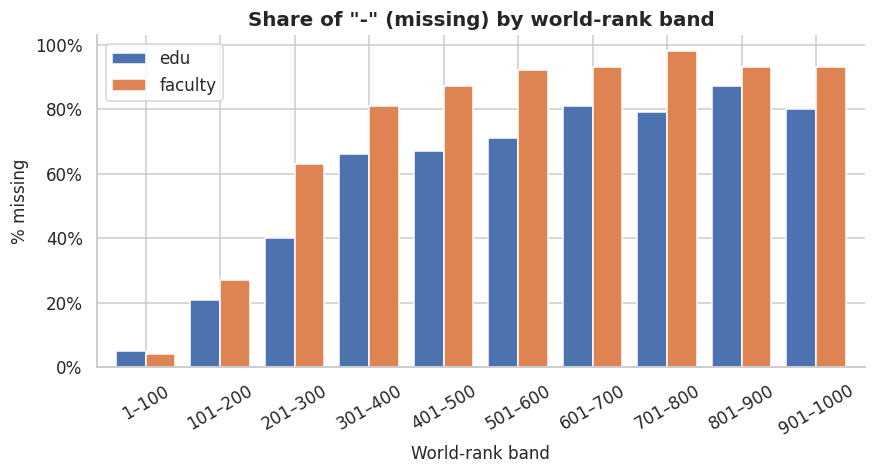

**Quality of Education** – 59.7% missing. Mean world rank of missing rows = 618 vs 326 for observed (Mann–Whitney p = 1.2e-55) → **missingness is related to rank (not random)**, so these two indicators are kept out of the main complete-case analyses.

**Quality of Faculty** – 73.1% missing. Mean world rank of missing rows = 603 vs 221 for observed (Mann–Whitney p = 1e-76) → **missingness is related to rank (not random)**, so these two indicators are kept out of the main complete-case analyses.

In [5]:
checks = {
    "world_rank unique":                       df.world_rank.is_unique,
    "score within [0, 100]":                   bool(df.score.between(0, 100).all()),
    "score non-increasing in world_rank":      bool(df.sort_values("world_rank").score.is_monotonic_decreasing),
    "national_rank ≤ n universities in country": bool((df.national_rank <= df.groupby("country").institution.transform("count")).all()),
    "core indicators fully observed":          bool(df[CORE].notna().all().all()),
}
display(pd.Series(checks, name="passed").to_frame())

# missingness vs. rank band
band = pd.cut(df.world_rank.astype(float), range(0, 1100, 100))
miss = df.groupby(band, observed=True)[["edu", "faculty"]].apply(lambda g: g.isna().mean()) * 100
miss.index = [f"{int(i.left) + 1}–{int(i.right)}" for i in miss.index]
fig, ax = plt.subplots(figsize=(9, 4))
miss.plot.bar(ax=ax, color=["#4c72b0", "#dd8452"], width=.8)
ax.set(title='Share of "-" (missing) by world-rank band', xlabel="World-rank band", ylabel="% missing")
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(title=None)
plt.xticks(rotation=30); plt.show(); save(fig, "01_missingness_by_rank")

for c in ["edu", "faculty"]:
    m = df[c].isna()
    if not m.any() or m.all():
        md(f"**{IND_LABEL[c]}** – no partial missingness to analyse."); continue
    u, p = stats.mannwhitneyu(df.loc[m, "world_rank"].astype(float), df.loc[~m, "world_rank"].astype(float))
    md(f"**{IND_LABEL[c]}** – {m.mean():.1%} missing. Mean world rank of missing rows = {df.loc[m,'world_rank'].astype(float).mean():.0f} vs "
       f"{df.loc[~m,'world_rank'].astype(float).mean():.0f} for observed (Mann–Whitney p = {p:.2g}) → "
       + ("**missingness is related to rank (not random)**, so these two indicators are kept out of the main complete-case analyses."
          if p < ALPHA else "no evidence that missingness depends on rank."))

**Takeaway.** The audit shows the original `isnull()` check was a false all-clear. The cleaning pipeline now preserves *what is known* (censoring flags, missing-pattern) instead of overwriting it, and the rest of the project uses the five fully-observed indicators (`alumni`, `research_output`, `quality_pubs`, `influence`, `citations`) for modelling, with `edu`/`faculty` used only descriptively.

<a class="anchor" id="univariate"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">One Variable at a Time</p>

**Goal:** understand the shape of every variable *before* choosing statistical tests. Skewness, heavy tails and censoring decide whether parametric tests (t-test, ANOVA, Pearson) are defensible or whether rank-based alternatives are required.

,count,mean,std,min,5%,25%,50%,75%,95%,max,skew,kurtosis,% censored,% missing
score,"1,000.000",75.034,4.671,69.800,70.100,71.500,73.750,77.300,84.400,100.000,1.442,2.480,0.000,0.000
edu,403.000,323.407,194.084,1.000,23.100,151.500,321.000,490.500,621.900,666.000,0.016,-1.216,0.000,59.700
alumni,"1,000.000",726.528,343.686,1.000,65.950,425.750,"1,001.000","1,001.000","1,001.000","1,001.000",-0.804,-0.918,50.900,0.000
faculty,269.000,144.818,88.637,1.000,14.400,68.000,140.000,223.000,287.000,303.000,0.134,-1.205,0.000,73.100
research_output,"1,000.000",508.454,300.080,1.000,50.950,250.750,500.500,754.250,"1,001.000","1,001.000",0.080,-1.157,7.700,0.000
quality_pubs,"1,000.000",503.003,292.855,1.000,50.950,250.750,500.500,750.250,"1,001.000","1,001.000",0.040,-1.160,5.100,0.000
influence,"1,000.000",529.156,322.419,1.000,50.950,250.750,502.500,814.750,"1,001.000","1,001.000",0.117,-1.266,17.100,0.000
citations,"1,000.000",501.159,308.875,1.000,50.950,240.000,460.000,673.000,"1,001.000","1,001.000",0.210,-1.164,11.000,0.000


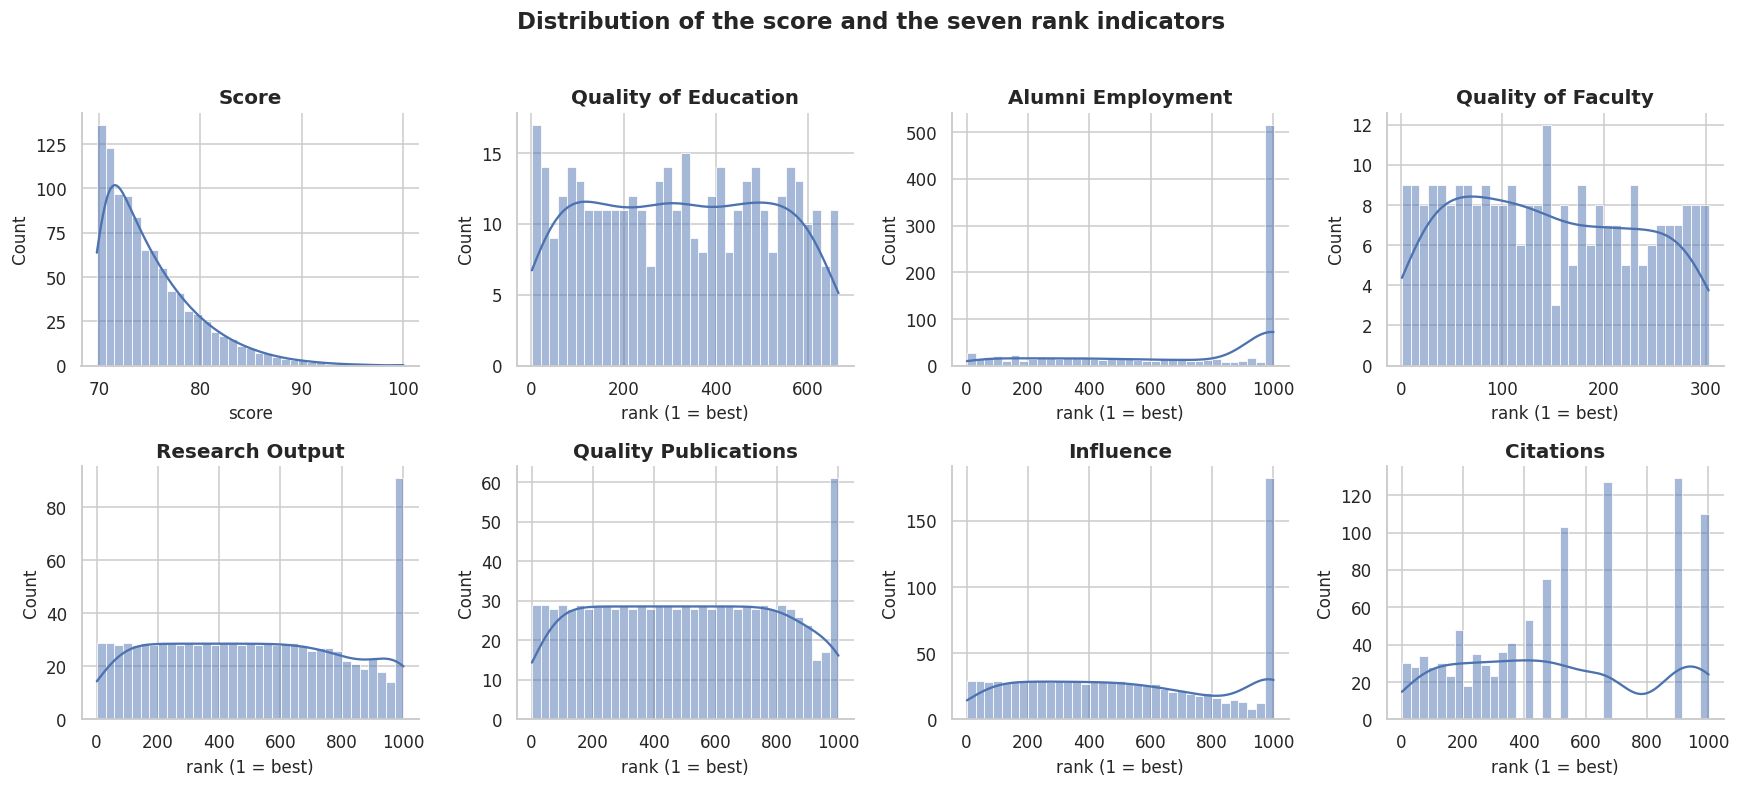

In [6]:
desc = df[["score"] + IND].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc["skew"] = df[["score"] + IND].skew()
desc["kurtosis"] = df[["score"] + IND].kurt()
desc["% censored"] = [0] + [df[f"{c}_censored"].mean() * 100 for c in IND]
desc["% missing"]  = df[["score"] + IND].isna().mean().values * 100
display(desc)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), ["score"] + IND):
    sns.histplot(df[c].dropna(), bins=35, kde=True, ax=ax, color="#4c72b0", edgecolor="white")
    ax.set_title(IND_LABEL.get(c, "Score")); ax.set_xlabel("rank (1 = best)" if c != "score" else "score")
fig.suptitle("Distribution of the score and the seven rank indicators", y=1.02, fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show(); save(fig, "02_distributions")

**How to read this.** `score` is strongly right-skewed (most universities cluster just above the lower cut-off; only a handful score near 100). The indicator histograms show a **spike at 1001** – that is the censored mass of universities whose rank on that indicator is “> 1000”, not a real value. Distribution shape matters for what follows.

,n,skew,excess kurtosis,D'Agostino K²,p (K²),Shapiro W,p (Shapiro),normal at α=.05?
variable,,,,,,,,
score,1000,1.440,2.461,263.927,0.000,0.874,0.000,no
log(score),1000,1.246,1.581,203.781,0.000,0.894,0.000,no
Alumni Employment,1000,-0.802,-0.920,228.506,0.000,0.767,0.000,no
Research Output,1000,0.080,-1.157,536.251,0.000,0.952,0.000,no
Quality Publications,1000,0.040,-1.160,545.379,0.000,0.957,0.000,no
Influence,1000,0.117,-1.265,"1,363.611",0.000,0.926,0.000,no
Citations,1000,0.210,-1.164,568.250,0.000,0.932,0.000,no


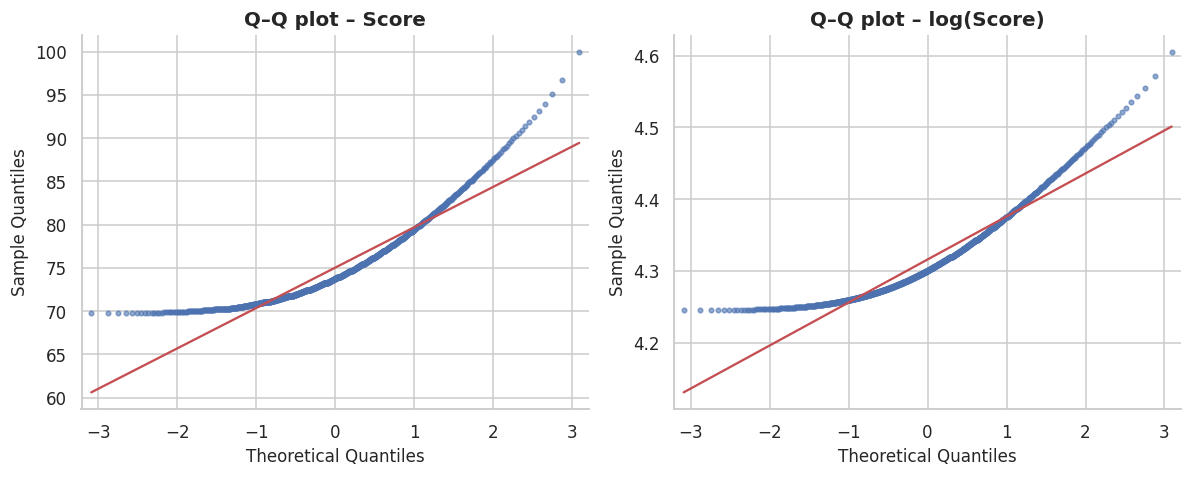

In [7]:
# Formal normality tests + Q–Q plots (score and log-score)
rows = []
for name, x in {"score": df.score, "log(score)": df.log_score, **{IND_LABEL[c]: df[c].dropna() for c in CORE}}.items():
    k2, p_k = stats.normaltest(x)
    w, p_w = stats.shapiro(x)
    rows.append({"variable": name, "n": len(x), "skew": stats.skew(x), "excess kurtosis": stats.kurtosis(x),
                 "D'Agostino K²": k2, "p (K²)": p_k, "Shapiro W": w, "p (Shapiro)": p_w,
                 "normal at α=.05?": "yes" if min(p_k, p_w) > ALPHA else "no"})
display(pd.DataFrame(rows).set_index("variable"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (x, t) in zip(axes, [(df.score, "Score"), (df.log_score, "log(Score)")]):
    sm.qqplot(x, line="s", ax=ax, markersize=3, alpha=.6); ax.set_title(f"Q–Q plot – {t}")
plt.tight_layout(); plt.show(); save(fig, "03_qq_score")

**Interpretation.** With n = 1000 even tiny departures from normality are “significant”, so the **Q–Q plot and skewness matter more than the p-value**. Points curving away from the line in the upper tail confirm heavy right skew; a log-transform helps but does not fully fix it. → **Decision:** use **non-parametric / rank-based tests** (Mann–Whitney, Kruskal–Wallis, Spearman) as the primary inference tools, and report parametric tests only as robustness checks.

### Which distribution describes the score best?
Fitting candidate families and comparing them by **AIC** (lower = better) and the KS distance gives a *probabilistic model* of the score. (Caveat: KS p-values are optimistic when parameters are estimated from the same data, so AIC and the visual fit lead the judgement.)

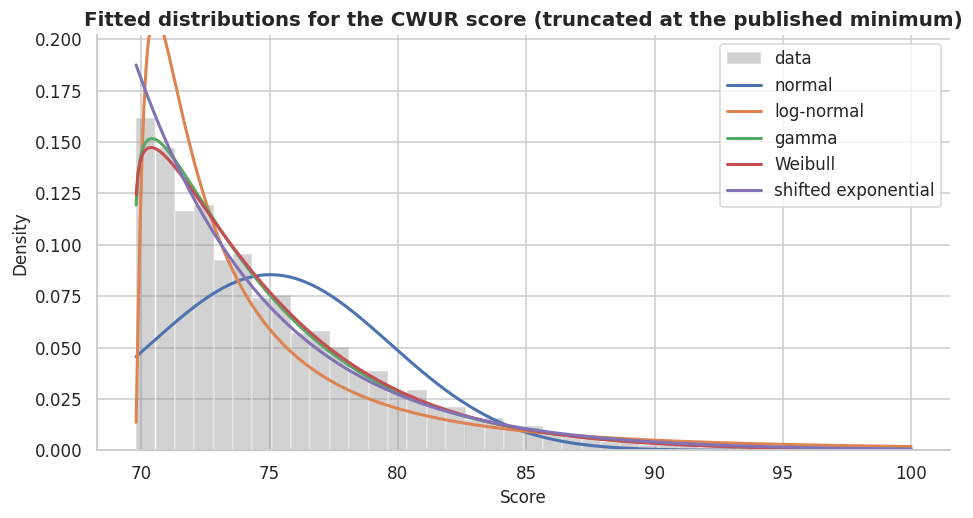

,AIC,KS distance,ΔAIC
distribution,,,
Weibull,"5,319.270",0.016,0.000
gamma,"5,322.514",0.020,3.244
shifted exponential,"5,331.480",0.039,12.210
log-normal,"5,511.919",0.083,192.649
normal,"5,923.562",0.131,604.292


**Best-fitting family by AIC: Weibull** (lowest KS distance: Weibull). Only the top 1000 institutions are published, so the score is a *right-skewed tail truncated near its minimum*; skewed families fit far better than the normal. AIC rewards overall likelihood while KS reports the largest CDF gap, so the two criteria need not agree.

In [8]:
cands = {"normal": stats.norm, "log-normal": stats.lognorm, "gamma": stats.gamma,
         "Weibull": stats.weibull_min, "shifted exponential": stats.expon}
x = df.score.values
loc0 = x.min() - 0.05            # only the top 1000 are published, so the score is truncated near its minimum: fix the location just below it
fits, grid = [], np.linspace(x.min(), x.max(), 400)
fig, ax = plt.subplots(figsize=(10, 5))
cnts, _, _ = ax.hist(x, bins=40, density=True, alpha=.35, color="grey", edgecolor="white", label="data")
for name, dist in cands.items():
    if name == "normal":
        params = dist.fit(x); k = 2
    else:
        params = dist.fit(x, floc=loc0); k = len(params) - 1       # location is fixed, not estimated
    ll = np.sum(dist.logpdf(x, *params))
    ks = stats.kstest(x, dist.cdf, args=params).statistic
    fits.append({"distribution": name, "AIC": 2 * k - 2 * ll, "KS distance": ks})
    ax.plot(grid, dist.pdf(grid, *params), lw=2, label=name)
ax.set_ylim(0, cnts.max() * 1.25)
ax.set(title="Fitted distributions for the CWUR score (truncated at the published minimum)", xlabel="Score", ylabel="Density"); ax.legend()
plt.show(); save(fig, "04_score_distribution_fits")
fit_tbl = pd.DataFrame(fits).sort_values("AIC").set_index("distribution"); fit_tbl["ΔAIC"] = fit_tbl.AIC - fit_tbl.AIC.min()
display(fit_tbl)
md(f"**Best-fitting family by AIC: {fit_tbl.index[0]}** (lowest KS distance: {fit_tbl['KS distance'].idxmin()}). "
   "Only the top 1000 institutions are published, so the score is a *right-skewed tail truncated near its minimum*; skewed families fit far better "
   "than the normal. AIC rewards overall likelihood while KS reports the largest CDF gap, so the two criteria need not agree.")

<a class="anchor" id="geography"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">Where Excellence Lives: Geography and Concentration</p>

Rankings are often discussed as a “US vs. the rest” story. Here we **quantify** the concentration instead of eyeballing a bar chart: share of institutions, over-representation in the Top 100, and an inequality index (Gini) over countries.

**61 countries** appear. The top-5 countries hold **49.7%** of all 1000 institutions; Gini of university counts across countries = **0.69**, Herfindahl index = **0.079** (equivalent to ≈ 12.7 equally-sized countries).

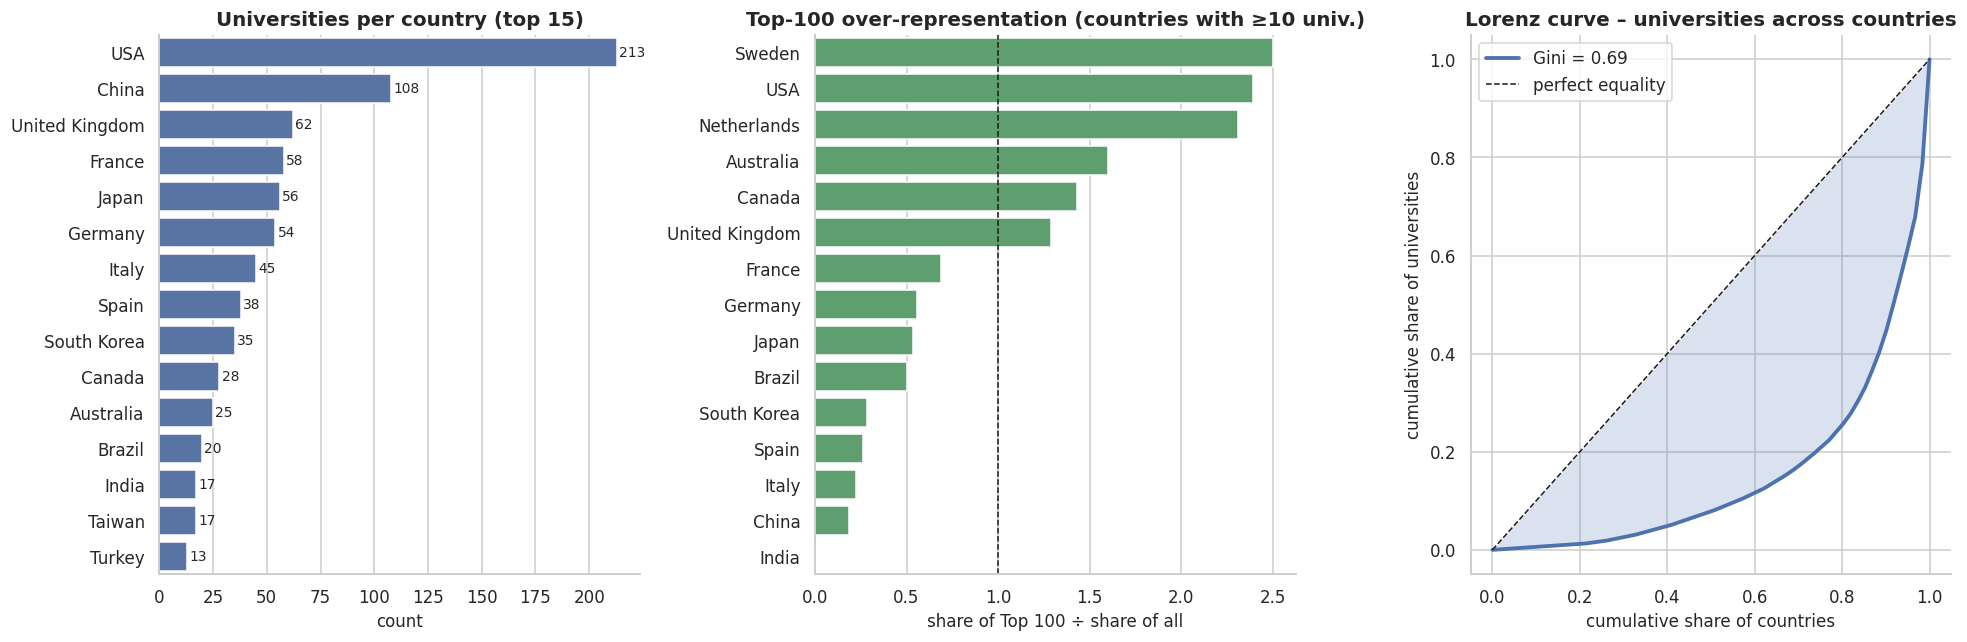

,n_universities,share_all,share_top100,over-representation index
USA,213,0.213,0.510,2.394
China,108,0.108,0.020,0.185
United Kingdom,62,0.062,0.080,1.290
France,58,0.058,0.040,0.690
Japan,56,0.056,0.030,0.536
Germany,54,0.054,0.030,0.556
Italy,45,0.045,0.010,0.222
Spain,38,0.038,0.010,0.263
South Korea,35,0.035,0.010,0.286
Canada,28,0.028,0.040,1.429


In [9]:
cnt = df.country.value_counts()
share = cnt / cnt.sum()
top100_share = df[df.top100 == 1].country.value_counts(normalize=True)
rep = pd.DataFrame({"n_universities": cnt, "share_all": share, "share_top100": top100_share}).fillna(0)
rep["over-representation index"] = rep.share_top100 / rep.share_all      # >1 ⇒ more elite institutions than its size suggests

def gini(v):
    v = np.sort(np.asarray(v, float)); n = len(v)
    return 2 * np.sum(np.arange(1, n + 1) * v) / (n * v.sum()) - (n + 1) / n

hhi = (share ** 2).sum()
md(f"**{df.country.nunique()} countries** appear. The top-5 countries hold **{share.head(5).sum():.1%}** of all 1000 institutions; "
   f"Gini of university counts across countries = **{gini(cnt):.2f}**, Herfindahl index = **{hhi:.3f}** "
   f"(equivalent to ≈ {1/hhi:.1f} equally-sized countries).")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
top15 = cnt.head(15)
sns.barplot(x=top15.values, y=top15.index, ax=axes[0], color="#4c72b0")
axes[0].set(title="Universities per country (top 15)", xlabel="count", ylabel="")
for i, v in enumerate(top15.values): axes[0].text(v + 1, i, str(v), va="center", fontsize=9)

r15 = rep[rep.n_universities >= 10].sort_values("over-representation index", ascending=False).head(15)
sns.barplot(x=r15["over-representation index"], y=r15.index, ax=axes[1], color="#55a868")
axes[1].axvline(1, color="k", ls="--", lw=1)
axes[1].set(title="Top-100 over-representation (countries with ≥10 univ.)", xlabel="share of Top 100 ÷ share of all", ylabel="")

# Lorenz curve of university counts
srt = np.sort(cnt.values); lor = np.insert(np.cumsum(srt) / srt.sum(), 0, 0); xs = np.linspace(0, 1, len(lor))
axes[2].plot(xs, lor, lw=2.5, label=f"Gini = {gini(cnt):.2f}"); axes[2].plot([0, 1], [0, 1], "k--", lw=1, label="perfect equality")
axes[2].fill_between(xs, lor, xs, alpha=.2)
axes[2].set(title="Lorenz curve – universities across countries", xlabel="cumulative share of countries", ylabel="cumulative share of universities"); axes[2].legend()
plt.tight_layout(); plt.show(); save(fig, "05_geography")
display(rep.sort_values("n_universities", ascending=False).head(12))

**Reading the figure.** The left panel shows *size*; the middle panel shows *quality concentration*: an index above 1 means a country places more universities in the Top 100 than its size would predict. The Lorenz curve (right) shows how unequally universities are distributed across countries – a few countries account for most institutions. Whether differences in *score* between regions are statistically real is tested in [Are the Differences Real? Statistical Inference](#inference).

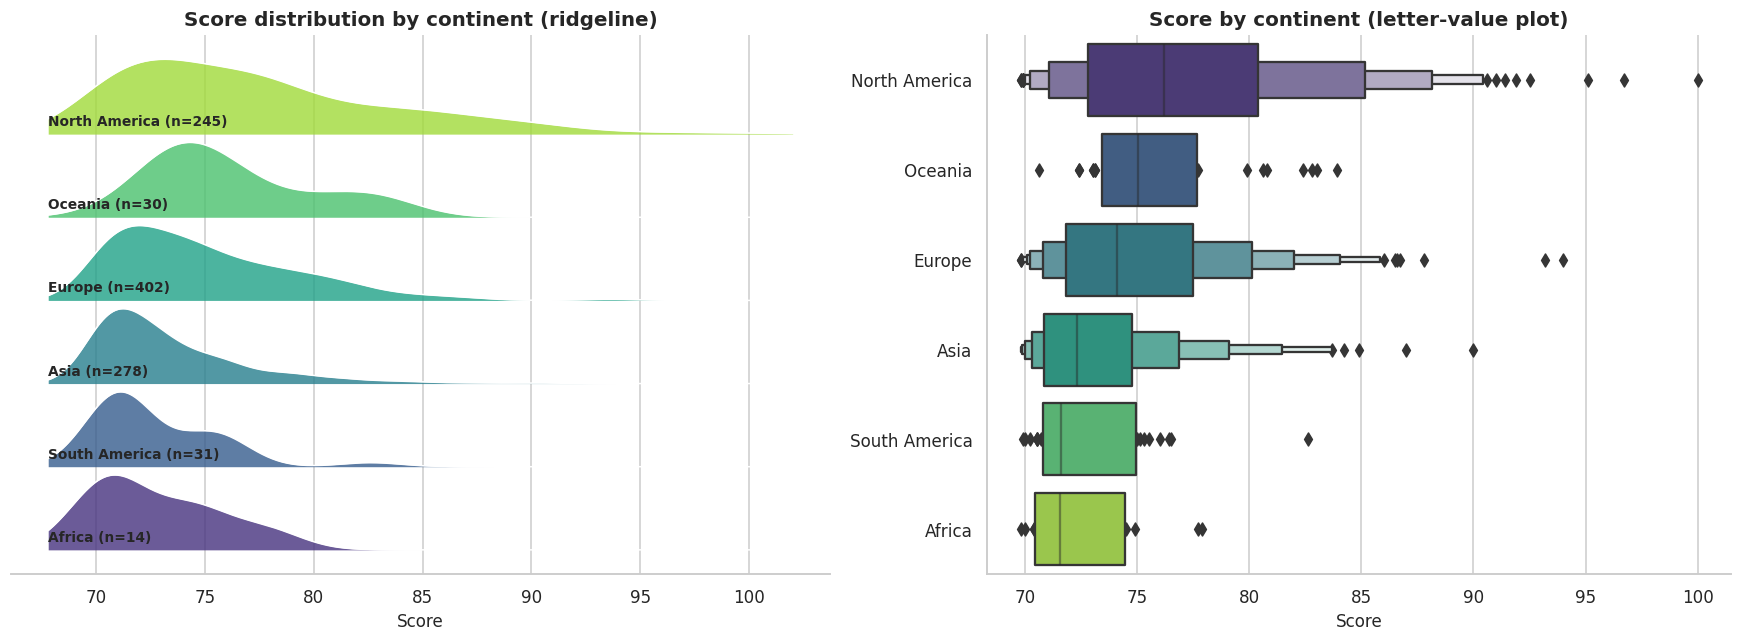

In [10]:
# Score distribution by continent: ridgeline (KDE) + strip, ordered by median
order = df.groupby("continent").score.median().sort_values(ascending=False).index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.1, 1]})
pal = sns.color_palette("viridis", len(order))
xs = np.linspace(df.score.min() - 2, df.score.max() + 2, 300)
for i, cont in enumerate(order[::-1]):
    v = df.loc[df.continent == cont, "score"]
    if len(v) < 3: continue
    d = stats.gaussian_kde(v)(xs); d = d / d.max() * 0.9
    axes[0].fill_between(xs, i, i + d, color=pal[i], alpha=.8, lw=0); axes[0].plot(xs, i + d, color="white", lw=1)
    axes[0].text(xs[0], i + .1, f"{cont} (n={len(v)})", fontsize=9, fontweight="bold")
axes[0].set(title="Score distribution by continent (ridgeline)", xlabel="Score", yticks=[]); axes[0].spines["left"].set_visible(False)
sns.boxenplot(data=df, y="continent", x="score", order=order, ax=axes[1], palette="viridis")
axes[1].set(title="Score by continent (letter-value plot)", xlabel="Score", ylabel="")
plt.tight_layout(); plt.show(); save(fig, "06_continent_scores")

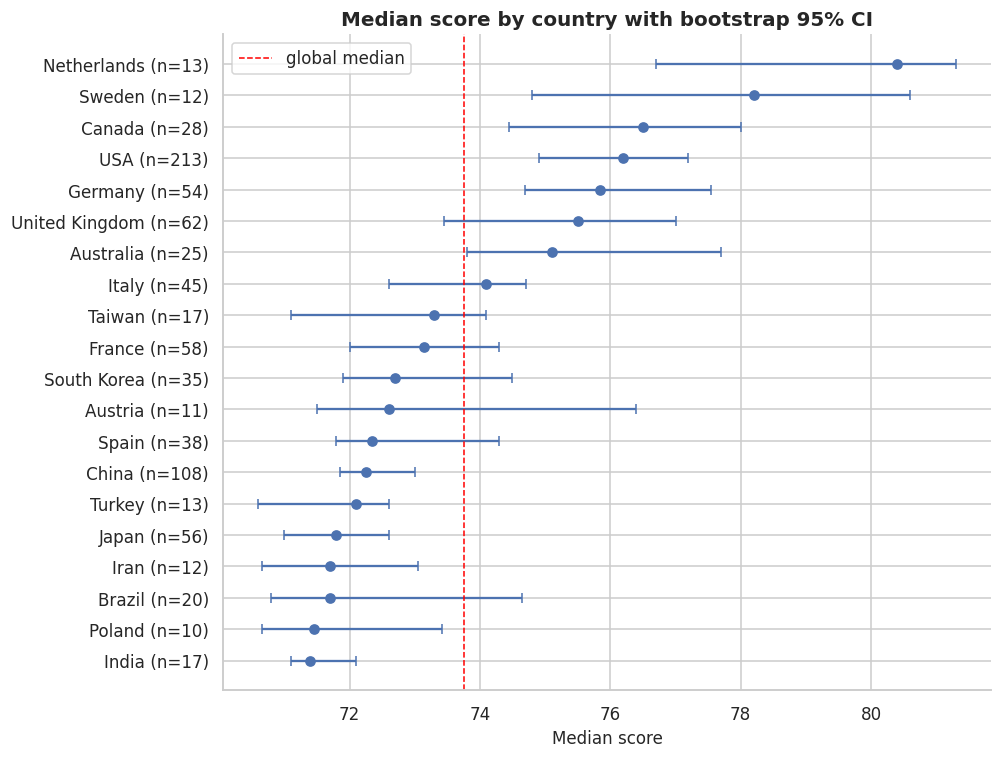

In [11]:
# Country medians with bootstrap 95% CIs (countries with >= 10 institutions)
def boot_ci(v, stat=np.median, B=2000, level=.95):
    v = np.asarray(v); idx = rng.integers(0, len(v), (B, len(v)))
    bs = stat(v[idx], axis=1); a = (1 - level) / 2
    return np.quantile(bs, [a, 1 - a])

big_c = cnt[cnt >= 10].index
rows = [{"country": c, "n": cnt[c], "median": df.loc[df.country == c, "score"].median(),
         **dict(zip(["lo", "hi"], boot_ci(df.loc[df.country == c, "score"].values)))} for c in big_c]
cm = pd.DataFrame(rows).sort_values("median")
fig, ax = plt.subplots(figsize=(9, 0.32 * len(cm) + 1.5))
ax.errorbar(cm["median"], range(len(cm)), xerr=[cm["median"] - cm.lo, cm.hi - cm["median"]], fmt="o", color="#4c72b0", capsize=3)
ax.set_yticks(range(len(cm))); ax.set_yticklabels([f"{c} (n={n})" for c, n in zip(cm.country, cm.n)])
ax.axvline(df.score.median(), color="red", ls="--", lw=1, label="global median"); ax.legend()
ax.set(title="Median score by country with bootstrap 95% CI", xlabel="Median score")
plt.show(); save(fig, "07_country_median_ci")

In [12]:
# Optional interactive choropleth (renders on Kaggle / locally; static PNGs above are used on GitHub)
try:
    import plotly.express as px
    iso_name = {"USA": "United States", "Slovak Republic": "Slovakia"}
    geo = df.groupby("country").agg(n=("institution", "size"), median_score=("score", "median")).reset_index()
    geo["geo_name"] = geo.country.replace(iso_name)
    fig = px.choropleth(geo, locations="geo_name", locationmode="country names", color="n",
                        hover_data=["median_score"], color_continuous_scale="Viridis",
                        title="Number of ranked universities per country")
    fig.update_layout(margin=dict(l=0, r=0, t=50, b=0)); fig.show()
except Exception as e:
    print("Plotly map skipped:", e)

<a class="anchor" id="relationships"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">How the Indicators Move Together</p>

The original notebook drew one scatter plot per variable on a 16×10 canvas. Here the same questions are answered with **fewer, denser, more informative plots**: a rank-correlation matrix (robust to skew and monotone non-linearity), a clustered version that reveals indicator families, LOWESS smoothers instead of raw scatter, and group profiles.

We use **Spearman’s ρ** (rank correlation) because relationships are monotone but not linear, and the data are ranks to begin with. Strength columns (`*_str`, higher = better) are used so that *positive ρ = “better on this indicator ↔ higher score”*.

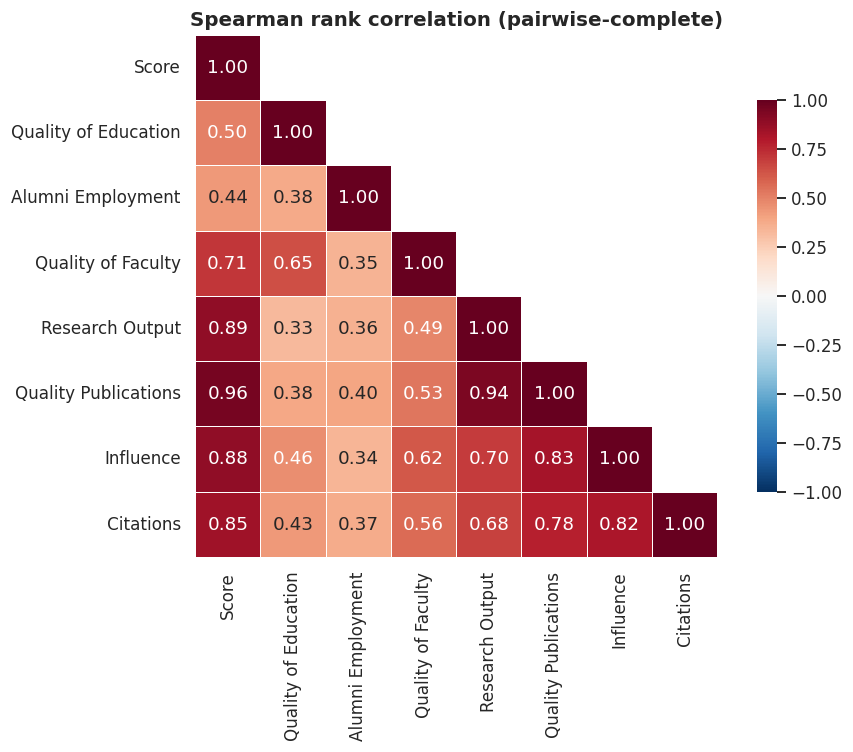

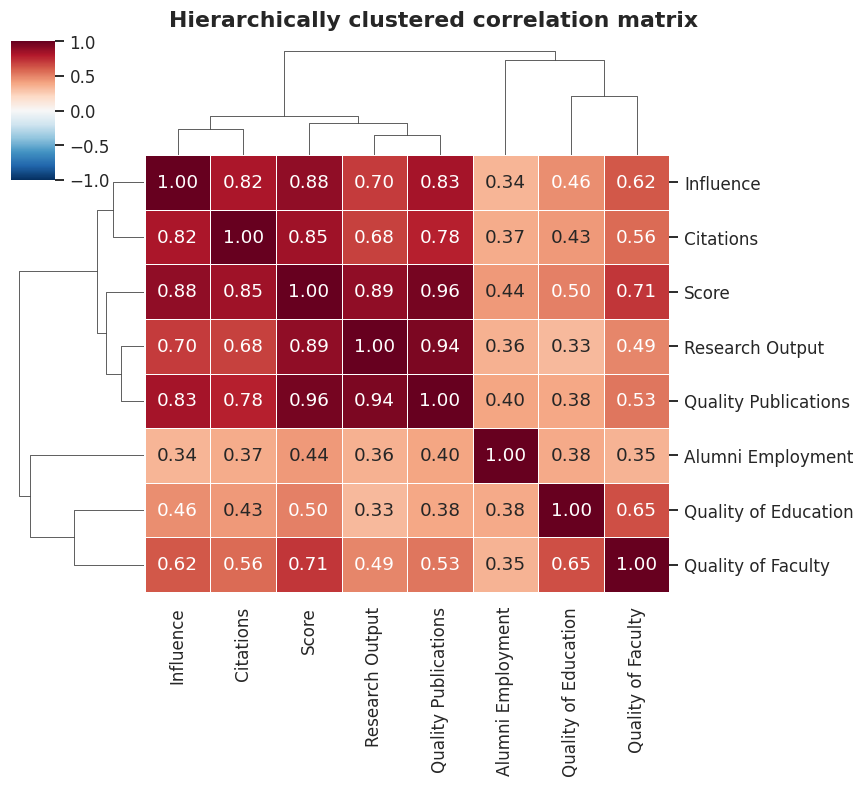

In [13]:
STR = [f"{c}_str" for c in IND]
LAB = {f"{c}_str": IND_LABEL[c] for c in IND}; LAB["score"] = "Score"
corr = df[["score"] + STR].rename(columns=LAB).corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"shrink": .75}, ax=ax, linewidths=.5)
ax.set_title("Spearman rank correlation (pairwise-complete)")
plt.tight_layout(); plt.show(); save(fig, "08_spearman_heatmap")

cg = sns.clustermap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, figsize=(8, 7), linewidths=.5)
cg.fig.suptitle("Hierarchically clustered correlation matrix", y=1.02, fontweight="bold"); plt.show(); save(cg.fig, "09_clustermap")

**Interpretation.** Look for *blocks*: the research indicators (`Research Output`, `Quality Publications`, `Influence`, `Citations`) should correlate strongly with each other (they measure variations of the same thing – research prowess), while `Alumni Employment` and the two sparse indicators capture reputation/prestige and tend to be a separate branch in the dendrogram. High inter-correlation within the research block warns of **multicollinearity** in regression (checked with VIF in [Explaining the Score: Regression and Diagnostics](#regression)).

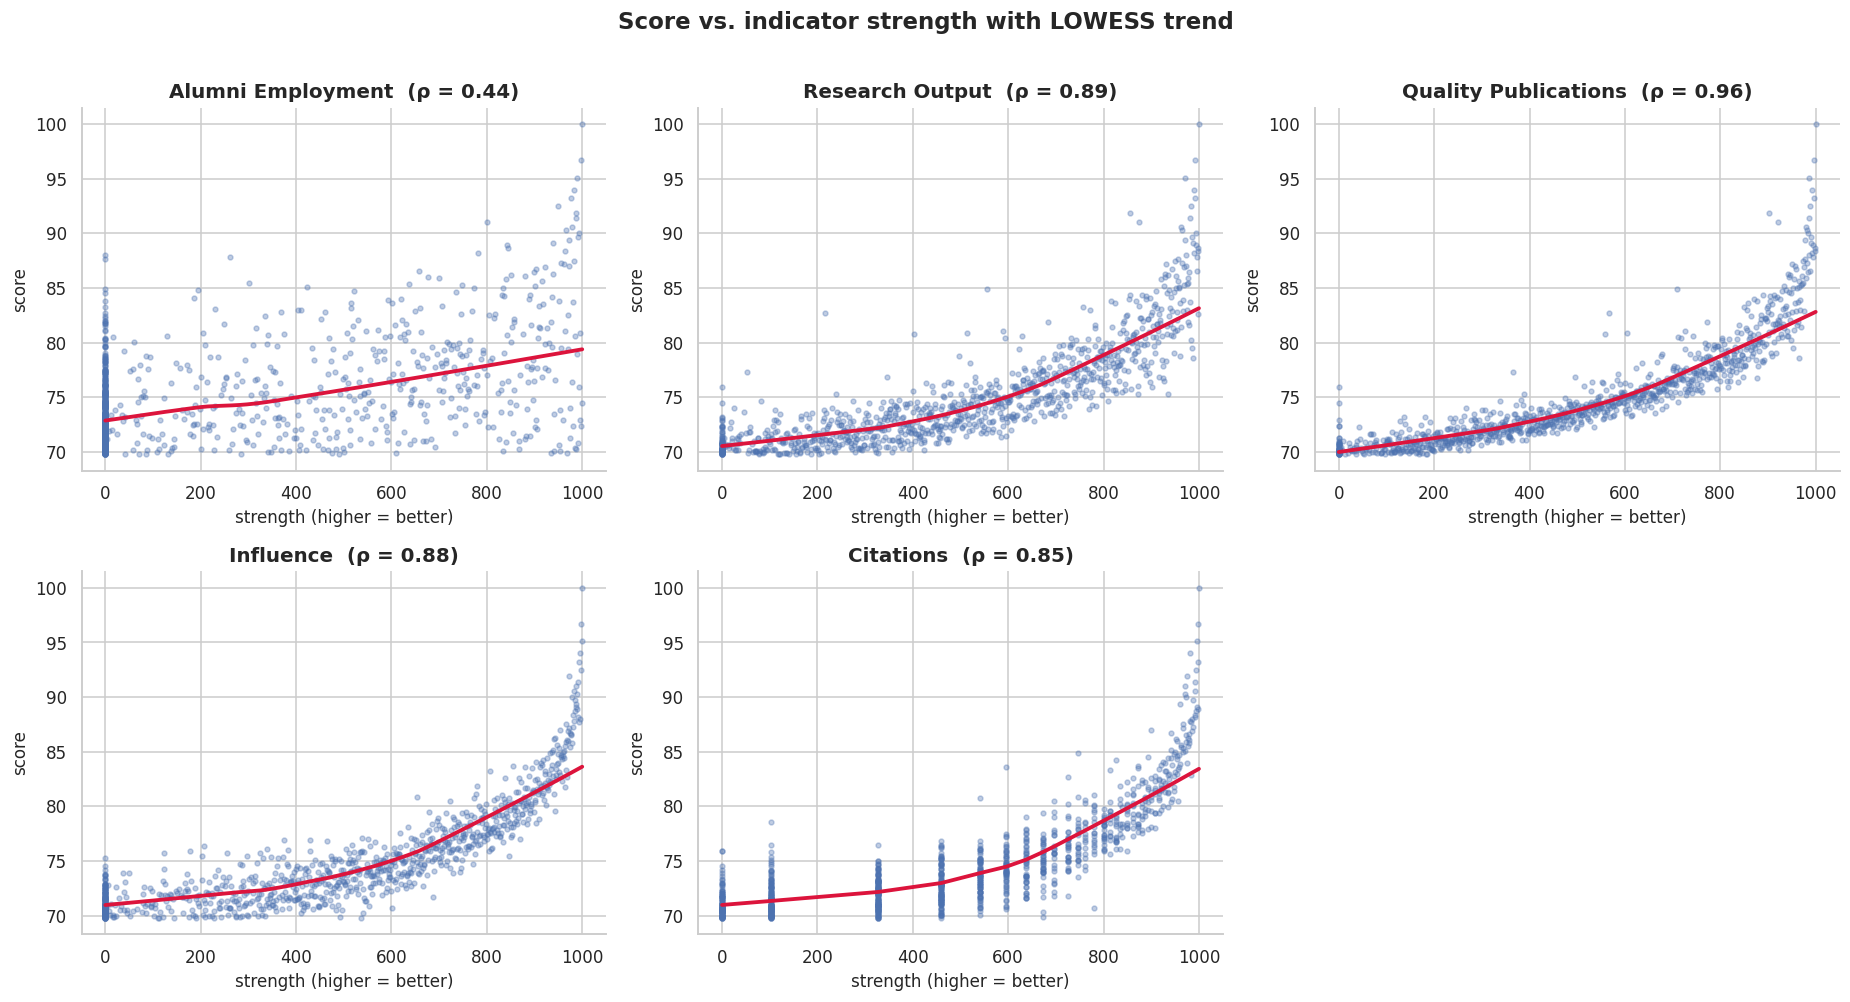

In [14]:
# LOWESS smoothers: score vs. each fully-observed indicator (strength scale)
fig, axes = plt.subplots(2, 3, figsize=(17, 9)); axes = axes.ravel()
for ax, c in zip(axes, CORE):
    sns.regplot(x=f"{c}_str", y="score", data=df, lowess=True, ax=ax,
                scatter_kws=dict(s=10, alpha=.35, color="#4c72b0"), line_kws=dict(color="crimson", lw=2.5))
    rho, p = stats.spearmanr(df[f"{c}_str"], df.score)
    ax.set_title(f"{IND_LABEL[c]}  (ρ = {rho:.2f})"); ax.set_xlabel("strength (higher = better)")
axes[-1].remove()
fig.suptitle("Score vs. indicator strength with LOWESS trend", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show(); save(fig, "10_lowess_grid")

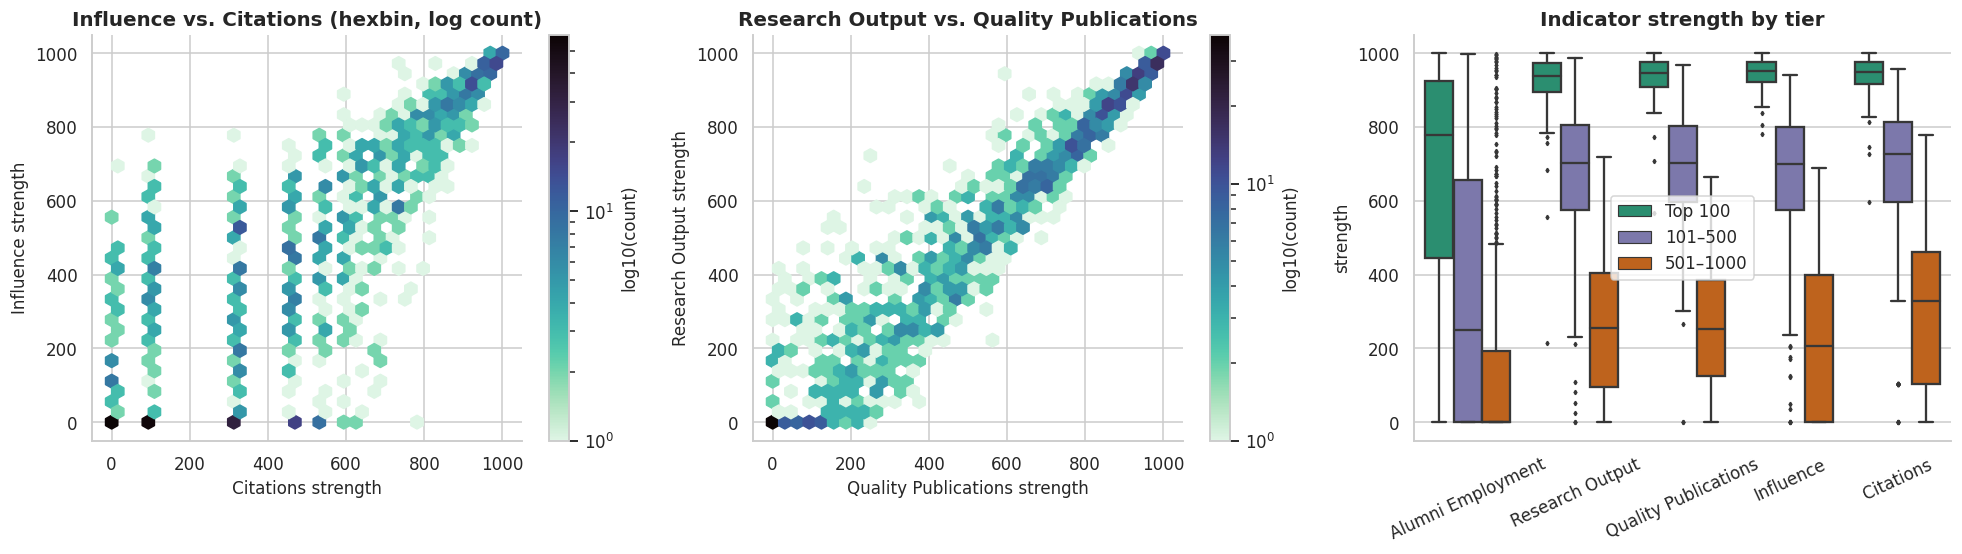

In [15]:
# Density view of the most related pair + distributions by tier
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
hb = axes[0].hexbin(df.citations_str, df.influence_str, gridsize=32, bins="log", cmap="mako_r", mincnt=1)
axes[0].set(title="Influence vs. Citations (hexbin, log count)", xlabel="Citations strength", ylabel="Influence strength")
plt.colorbar(hb, ax=axes[0], label="log10(count)")
hb2 = axes[1].hexbin(df.quality_pubs_str, df.research_output_str, gridsize=32, bins="log", cmap="mako_r", mincnt=1)
axes[1].set(title="Research Output vs. Quality Publications", xlabel="Quality Publications strength", ylabel="Research Output strength")
plt.colorbar(hb2, ax=axes[1], label="log10(count)")
long = df.melt(id_vars="tier", value_vars=[f"{c}_str" for c in CORE], var_name="indicator", value_name="strength")
long["indicator"] = long.indicator.str.replace("_str", "").map(IND_LABEL)
sns.boxplot(data=long, x="indicator", y="strength", hue="tier", hue_order=TIER_ORDER, palette=TIER_PAL, ax=axes[2], fliersize=2)
axes[2].set(title="Indicator strength by tier", xlabel="", ylabel="strength"); axes[2].tick_params(axis="x", rotation=25); axes[2].legend(title=None)
plt.tight_layout(); plt.show(); save(fig, "11_density_and_tiers")

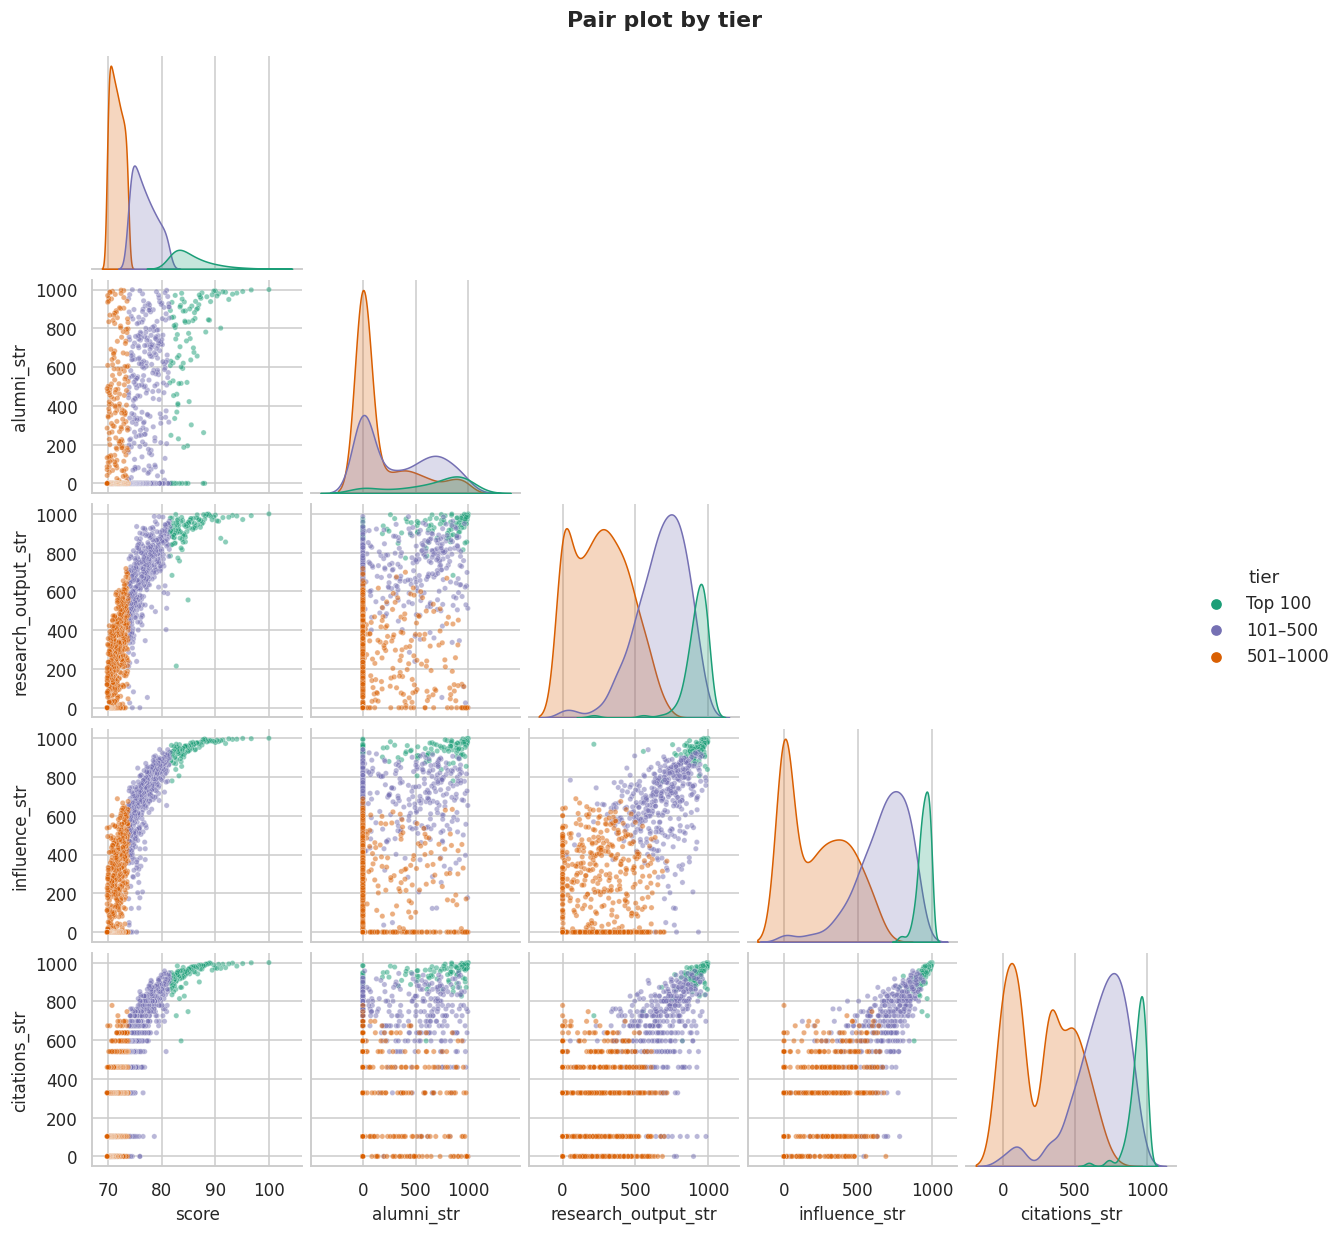

In [16]:
# Multivariate overview: pair plot coloured by tier
pp = sns.pairplot(df, vars=["score", "alumni_str", "research_output_str", "influence_str", "citations_str"],
                  hue="tier", hue_order=TIER_ORDER, palette=TIER_PAL, corner=True, diag_kind="kde",
                  plot_kws=dict(s=12, alpha=.5), height=2.2)
pp.fig.suptitle("Pair plot by tier", y=1.02, fontweight="bold"); plt.show(); save(pp.fig, "12_pairplot")

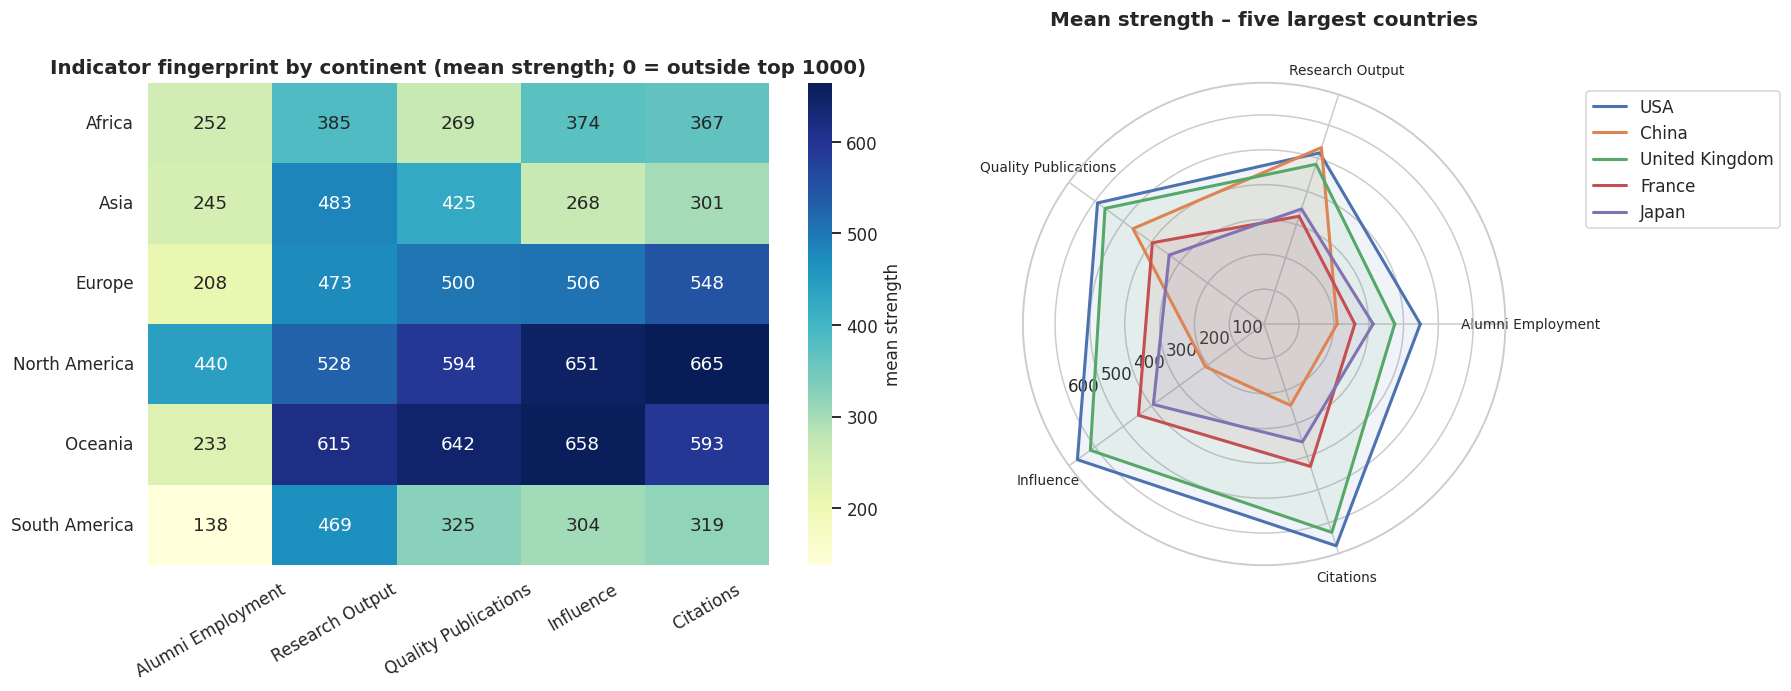

In [17]:
# Continent "fingerprint": mean strength on every indicator, and a radar of the biggest countries
# only the five fully-observed indicators: edu/faculty exist for a rank-biased subset, so their medians would mislead
# mean strength: a university whose rank is "> 1000" counts as 0 ("outside the top 1000"), so the mean reflects how many are inside AND how high
prof = df.groupby("continent")[[f"{c}_str" for c in CORE]].mean().rename(columns=LAB)
prof = prof.loc[df.groupby("continent").size().loc[lambda s: s >= 10].index]
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(prof, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "mean strength"})
axes[0].set(title="Indicator fingerprint by continent (mean strength; 0 = outside top 1000)", ylabel="")
axes[0].tick_params(axis="x", rotation=30); axes[0].tick_params(axis="y", rotation=0)
axes[1].remove()
ax = fig.add_subplot(1, 2, 2, polar=True)
top_c = cnt.head(5).index; angles = np.linspace(0, 2 * np.pi, len(CORE), endpoint=False).tolist(); angles += angles[:1]
for c in top_c:
    vals = df.loc[df.country == c, [f"{k}_str" for k in CORE]].mean().tolist(); vals += vals[:1]
    ax.plot(angles, vals, lw=2, label=c); ax.fill(angles, vals, alpha=.08)
ax.set_xticks(angles[:-1]); ax.set_xticklabels([IND_LABEL[k] for k in CORE], fontsize=9); ax.set_title("Mean strength – five largest countries", y=1.1)
ax.legend(loc="upper left", bbox_to_anchor=(1.15, 1.0)); ax.set_rlabel_position(200)
plt.tight_layout(); plt.show(); save(fig, "13_profiles_radar")

<a class="anchor" id="leakage"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">Rank vs. Score: A Leakage Warning</p>

The original notebook’s very first plot was *Score vs. World Rank*. It is worth understanding why that plot is uninformative for modelling: **`world_rank` is simply the ordering of `score`**. Likewise `score` is a *weighted aggregate of the indicators*. Any model that predicts `score` or `world_rank` from the indicators is therefore **reverse-engineering a formula, not discovering a pattern** – this is *target leakage by construction*.

What it *is* good for: describing the **shape** of the ranking (steep decline at the top, long plateau below), and validating the data.

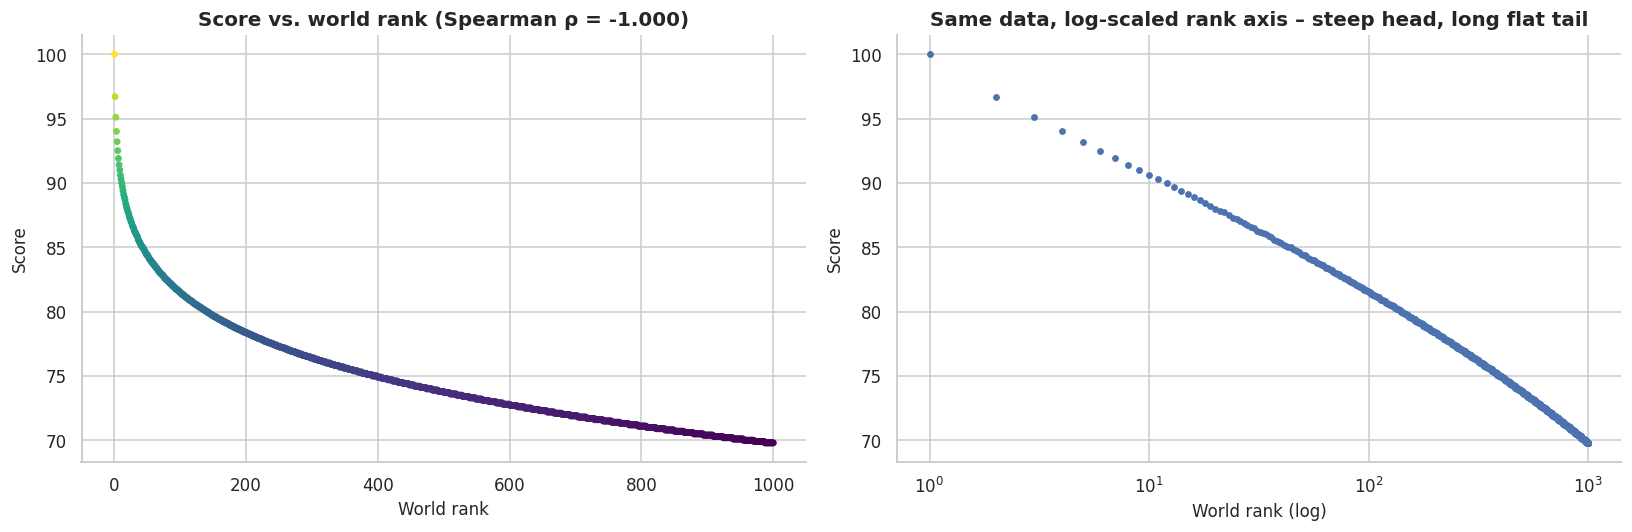

The score falls from **100.0** (rank 1) to **81.5** at rank 100, but only to **73.8** at rank 500 and **69.8** at rank 1000. The *top 100 are separated by large score gaps; the bottom 500 are separated by almost nothing*, so differences between rank 700 and 800 are essentially noise – a key caveat for anyone using the ranking.

In [18]:
rho_rs, _ = stats.spearmanr(df.world_rank.astype(float), df.score)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sc = axes[0].scatter(df.world_rank.astype(float), df.score, c=df.score, cmap="viridis", s=12)
axes[0].set(title=f"Score vs. world rank (Spearman ρ = {rho_rs:.3f})", xlabel="World rank", ylabel="Score")
axes[1].scatter(df.world_rank.astype(float), df.score, s=12, color="#4c72b0"); axes[1].set_xscale("log")
axes[1].set(title="Same data, log-scaled rank axis – steep head, long flat tail", xlabel="World rank (log)", ylabel="Score")
plt.tight_layout(); plt.show(); save(fig, "14_rank_vs_score")

drop_pts = df.sort_values("world_rank").score.values
md(f"The score falls from **{drop_pts[0]:.1f}** (rank 1) to **{drop_pts[99]:.1f}** at rank 100, but only to **{drop_pts[499]:.1f}** at rank 500 and **{drop_pts[-1]:.1f}** at rank 1000. "
   f"The *top 100 are separated by large score gaps; the bottom 500 are separated by almost nothing*, so differences between rank 700 and 800 are essentially noise – a key caveat for anyone using the ranking.")

<a class="anchor" id="inference"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">Are the Differences Real? Statistical Inference</p>

**Framework.** For each hypothesis: state H₀/H₁ → justify the test from the diagnostics in [One Variable at a Time](#univariate) → report the **test statistic, p-value, an effect size, and an interval** → interpret in plain language. A p-value alone says only whether an effect is *detectable*; the **effect size says whether it is *large enough to matter***. All p-values are collected in one registry and corrected for multiple testing (Holm & Benjamini–Hochberg) at the end of the section.

Helper functions used below:

In [19]:
REGISTRY = []
def register(hypothesis, test, stat, p, eff_name, eff, n):
    REGISTRY.append(dict(hypothesis=hypothesis, test=test, statistic=stat, p_value=p, effect_size=eff_name, effect=eff, n=n))

def cliffs_delta(x, y):
    # P(X > Y) − P(X < Y)  ∈ [−1, 1];   |δ| ≈ .147 small, .33 medium, .474 large (Romano et al.)
    u = stats.mannwhitneyu(x, y, alternative="two-sided").statistic
    return 2 * u / (len(x) * len(y)) - 1

def magnitude(d):
    d = abs(d); return "negligible" if d < .147 else "small" if d < .33 else "medium" if d < .474 else "large"

def cramers_v(table):
    chi2 = stats.chi2_contingency(table, correction=False)[0]; n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

def verdict(p):  return "reject H₀" if p < ALPHA else "fail to reject H₀"

MIN_N = 10
big_cont = df.continent.value_counts().loc[lambda s: s >= MIN_N].index.tolist()
sub = df[df.continent.isin(big_cont)]
print("Continents with n ≥", MIN_N, "→", big_cont)

Continents with n ≥ 10 → ['Europe', 'Asia', 'North America', 'South America', 'Oceania', 'Africa']


### H1 · Do continents differ in score? (omnibus test)
* **H₀:** the score distribution is the same for all continents.  **H₁:** at least one continent differs.
* **Test choice:** scores are skewed and group sizes are very unequal → **Kruskal–Wallis** (rank-based). First check variance homogeneity with **Brown–Forsythe/Levene (median-centred)** to know whether differences are only in *location* or also in *spread*. A classical one-way ANOVA is reported as a robustness check only.
* **Effect size:** ε² = H·(n+1)/(n²−1) (≈ share of rank variance explained; .01 small, .08 medium, .26 large).

In [20]:
groups = [g.score.values for _, g in sub.groupby("continent")]
lev_w, lev_p = stats.levene(*groups, center="median")
H, p_kw = stats.kruskal(*groups)
n_tot = len(sub); eps2 = H * (n_tot + 1) / (n_tot ** 2 - 1)
F, p_f = stats.f_oneway(*groups)
register("H1 continents differ in score", "Kruskal–Wallis", H, p_kw, "ε²", eps2, n_tot)

md(f"""
| Test | Statistic | p-value | Conclusion |
|---|---|---|---|
| Brown–Forsythe (equal spread) | W = {lev_w:.2f} | {lev_p:.3g} | {'spreads differ' if lev_p < ALPHA else 'no evidence spreads differ'} |
| **Kruskal–Wallis** | H = {H:.2f} | **{p_kw:.3g}** | **{verdict(p_kw)}** |
| One-way ANOVA (robustness) | F = {F:.2f} | {p_f:.3g} | {verdict(p_f)} |

**Effect size ε² = {eps2:.3f}** → {'large' if eps2>.26 else 'medium' if eps2>.08 else 'small' if eps2>.01 else 'negligible'}.
""")


| Test | Statistic | p-value | Conclusion |
|---|---|---|---|
| Brown–Forsythe (equal spread) | W = 16.90 | 4.7e-16 | spreads differ |
| **Kruskal–Wallis** | H = 99.87 | **5.63e-20** | **reject H₀** |
| One-way ANOVA (robustness) | F = 24.31 | 3.88e-23 | reject H₀ |

**Effect size ε² = 0.100** → medium.


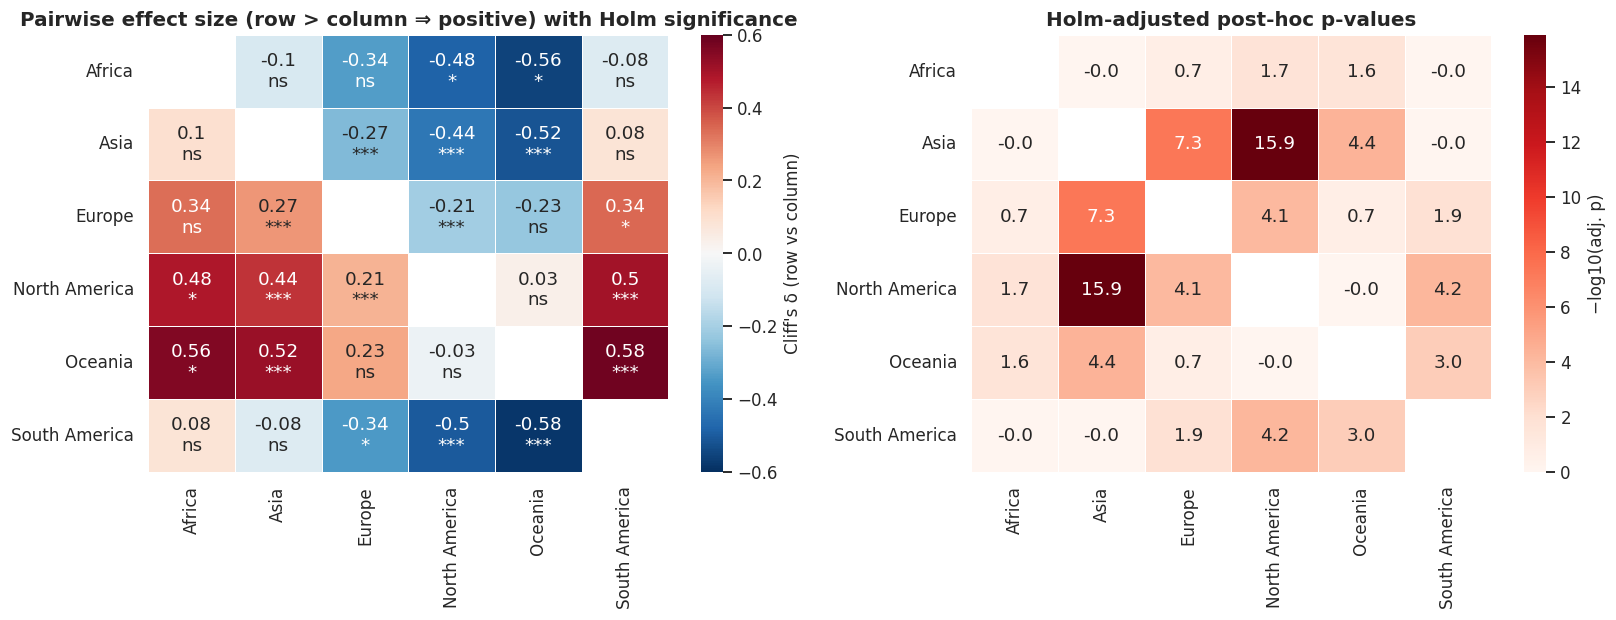

,A,B,p_raw,cliffs_delta,p_holm
6,Asia,North America,0.000,-0.435,0.000
5,Asia,Europe,0.000,-0.266,0.000
7,Asia,Oceania,0.000,-0.518,0.000
13,North America,South America,0.000,0.503,0.000
9,Europe,North America,0.000,-0.210,0.000
14,Oceania,South America,0.000,0.583,0.001
11,Europe,South America,0.001,0.343,0.013
2,Africa,North America,0.002,-0.485,0.019


In [21]:
# Post-hoc: all pairwise Mann–Whitney tests, Holm-adjusted; effect size = Cliff's δ
pairs = list(itertools.combinations(sorted(big_cont), 2))
res = []
for a, b in pairs:
    xa, xb = sub.loc[sub.continent == a, "score"], sub.loc[sub.continent == b, "score"]
    res.append((a, b, stats.mannwhitneyu(xa, xb).pvalue, cliffs_delta(xa, xb)))
post = pd.DataFrame(res, columns=["A", "B", "p_raw", "cliffs_delta"])
post["p_holm"] = multipletests(post.p_raw, method="holm")[1]
P = pd.DataFrame(np.nan, index=sorted(big_cont), columns=sorted(big_cont)); D = P.copy()
for _, r in post.iterrows():
    P.loc[r.A, r.B] = P.loc[r.B, r.A] = r.p_holm; D.loc[r.A, r.B] = r.cliffs_delta; D.loc[r.B, r.A] = -r.cliffs_delta
annot = P.apply(lambda col: col.map(lambda v: "" if pd.isna(v) else stars(v)))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
sns.heatmap(D, annot=D.round(2).astype(str) + "\n" + annot, fmt="", cmap="RdBu_r", center=0, vmin=-.6, vmax=.6, ax=axes[0],
            cbar_kws={"label": "Cliff's δ (row vs column)"}, linewidths=.5)
axes[0].set_title("Pairwise effect size (row > column ⇒ positive) with Holm significance")
sns.heatmap(-np.log10(P.astype(float)), annot=True, fmt=".1f", cmap="Reds", ax=axes[1], cbar_kws={"label": "−log10(adj. p)"}, linewidths=.5)
axes[1].set_title("Holm-adjusted post-hoc p-values")
[a.tick_params(axis="y", rotation=0) for a in axes]
plt.tight_layout(); plt.show(); save(fig, "15_posthoc_continents")
display(post.sort_values("p_holm").head(8))

**Reading it.** Red cells in the left matrix mean the *row* continent tends to score higher than the *column* continent (δ = probability row > column minus probability row < column). Stars mark pairs that stay significant **after** Holm’s family-wise correction. A significant pair with |δ| < .147 would be “statistically detectable but practically negligible” – the distinction that p-values alone hide.

### H2 · Is the leading country’s score higher than the rest of the world?
* **H₀:** the score distributions of the largest country and all other countries are identical (P(X > Y) = ½).  **H₁:** they differ.
* **Triangulation** – three independent approaches should agree: **Mann–Whitney U** (asymptotic), a **permutation test** on the *difference in medians* (no distributional assumptions), and a **bootstrap CI** for that difference. **Welch’s t-test on log(score)** is the parametric cross-check.
* **Effect sizes:** Cliff’s δ and the *common-language effect size* CLES = P(random university from group A outscores one from group B).

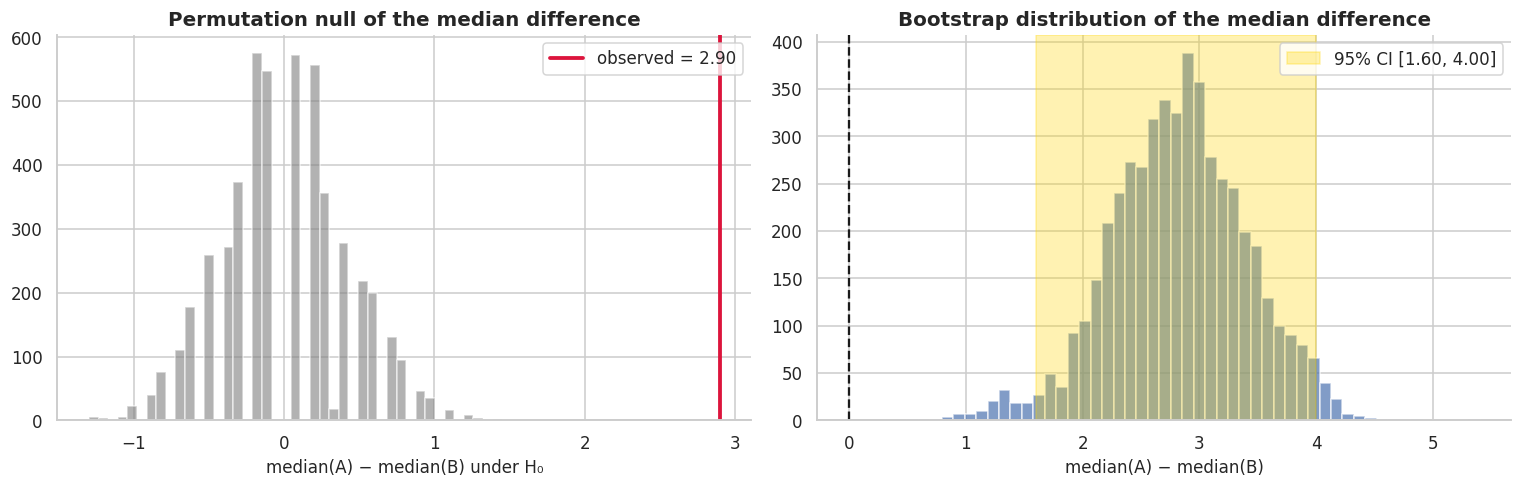


**USA** (n = 213) vs. **rest of world** (n = 787); median score 76.20 vs 73.30.

| Approach | Result | Conclusion |
|---|---|---|
| Mann–Whitney U | U = 108,618, p = 3.29e-11 | reject H₀ |
| Permutation test (median diff, 5,000 shuffles) | Δ = 2.90, p = 0.0002 | reject H₀ |
| Bootstrap 95% CI of Δ median | [1.60, 4.00] | excludes 0 |
| Welch t-test on log(score) | t = 6.97, p = 2.5e-11 | reject H₀ |

**Effect size:** Cliff’s δ = 0.30 (small); CLES = 64.8% → a randomly chosen USA university outscores a randomly chosen foreign one in about **65%** of pairings (50% = no difference).


In [22]:
TOP_C = cnt.index[0]
a = df.loc[df.country == TOP_C, "score"].values
b = df.loc[df.country != TOP_C, "score"].values
U, p_mw = stats.mannwhitneyu(a, b)
delta = cliffs_delta(a, b); cles = (delta + 1) / 2
t, p_t = stats.ttest_ind(np.log(a), np.log(b), equal_var=False)

obs = np.median(a) - np.median(b)
pooled = np.concatenate([a, b]); n_a = len(a); B = 5000
perm = np.empty(B)
for i in range(B):
    sh = rng.permutation(pooled); perm[i] = np.median(sh[:n_a]) - np.median(sh[n_a:])
p_perm = (np.sum(np.abs(perm) >= abs(obs)) + 1) / (B + 1)

bs = np.median(a[rng.integers(0, len(a), (B, len(a)))], axis=1) - np.median(b[rng.integers(0, len(b), (B, len(b)))], axis=1)
ci = np.quantile(bs, [.025, .975])
register(f"H2 {TOP_C} vs rest", "Mann–Whitney U", U, p_mw, "Cliff's δ", delta, len(df))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].hist(perm, bins=50, color="grey", alpha=.6, edgecolor="white"); axes[0].axvline(obs, color="crimson", lw=2.5, label=f"observed = {obs:.2f}")
axes[0].set(title="Permutation null of the median difference", xlabel="median(A) − median(B) under H₀"); axes[0].legend()
axes[1].hist(bs, bins=50, color="#4c72b0", alpha=.7, edgecolor="white"); axes[1].axvline(0, color="k", ls="--")
axes[1].axvspan(*ci, color="gold", alpha=.3, label=f"95% CI [{ci[0]:.2f}, {ci[1]:.2f}]")
axes[1].set(title="Bootstrap distribution of the median difference", xlabel="median(A) − median(B)"); axes[1].legend()
plt.tight_layout(); plt.show(); save(fig, "16_perm_bootstrap")

md(f"""
**{TOP_C}** (n = {len(a)}) vs. **rest of world** (n = {len(b)}); median score {np.median(a):.2f} vs {np.median(b):.2f}.

| Approach | Result | Conclusion |
|---|---|---|
| Mann–Whitney U | U = {U:,.0f}, p = {p_mw:.3g} | {verdict(p_mw)} |
| Permutation test (median diff, {B:,} shuffles) | Δ = {obs:.2f}, p = {p_perm:.4f} | {verdict(p_perm)} |
| Bootstrap 95% CI of Δ median | [{ci[0]:.2f}, {ci[1]:.2f}] | {'excludes 0' if (ci[0]>0 or ci[1]<0) else 'includes 0'} |
| Welch t-test on log(score) | t = {t:.2f}, p = {p_t:.3g} | {verdict(p_t)} |

**Effect size:** Cliff’s δ = {delta:.2f} ({magnitude(delta)}); CLES = {cles:.1%} → a randomly chosen {TOP_C} university outscores a randomly chosen foreign one in about **{cles:.0%}** of pairings (50% = no difference).
""")

**Statistical power & sensitivity.** A non-significant result is only informative if the test could have detected a meaningful effect. Conversely, with large samples even trivial effects reach significance. Power analysis quantifies both.

Observed Cohen’s d (log-score) = **0.67**. With the actual group sizes the test has 80% power to detect effects as small as **d = 0.22** (minimum detectable effect). To detect the *observed* effect with 80% power one would need only ≈ **36 per group**.

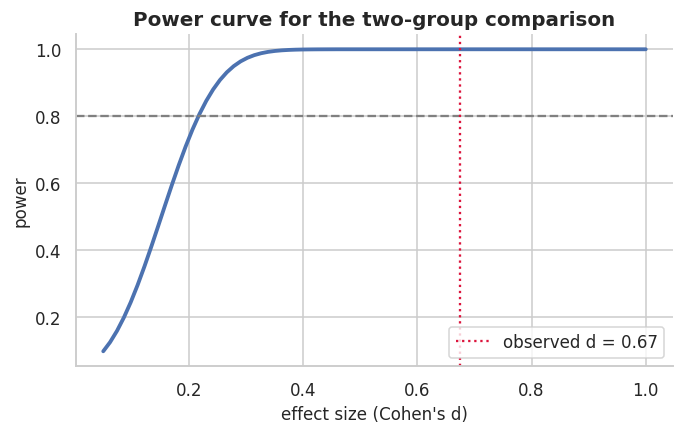

In [23]:
d_cohen = (np.log(a).mean() - np.log(b).mean()) / np.sqrt(((len(a)-1)*np.log(a).var(ddof=1) + (len(b)-1)*np.log(b).var(ddof=1)) / (len(a)+len(b)-2))
pw = TTestIndPower()
mde = pw.solve_power(effect_size=None, nobs1=len(a), ratio=len(b) / len(a), alpha=ALPHA, power=.8)
n_need = pw.solve_power(effect_size=abs(d_cohen), alpha=ALPHA, power=.8)
md(f"Observed Cohen’s d (log-score) = **{d_cohen:.2f}**. With the actual group sizes the test has 80% power to detect effects as small as **d = {mde:.2f}** "
   f"(minimum detectable effect). To detect the *observed* effect with 80% power one would need only ≈ **{np.ceil(n_need):.0f} per group**.")
fig, ax = plt.subplots(figsize=(7, 4))
effs = np.linspace(.05, 1, 80); ax.plot(effs, [pw.power(e, nobs1=len(a), ratio=len(b)/len(a), alpha=ALPHA) for e in effs], lw=2.5)
ax.axhline(.8, color="grey", ls="--"); ax.axvline(abs(d_cohen), color="crimson", ls=":", label=f"observed d = {abs(d_cohen):.2f}")
ax.set(title="Power curve for the two-group comparison", xlabel="effect size (Cohen's d)", ylabel="power"); ax.legend()
plt.show(); save(fig, "17_power_curve")

### H3 · Is a university’s *continent* associated with its *tier*? (chi-square test of independence)
* **H₀:** tier and continent are independent.  **H₁:** they are associated.
* **Test choice:** categorical × categorical → **χ² test of independence**. Because some cells have small counts, the asymptotic p-value is cross-checked with a **Monte-Carlo permutation p-value**.
* **Effect size:** **Cramér’s V** (.1 small, .3 medium, .5 large for df* = 2). **Standardised residuals** show *which cells* drive the association (|z| > 2 ≈ notable).

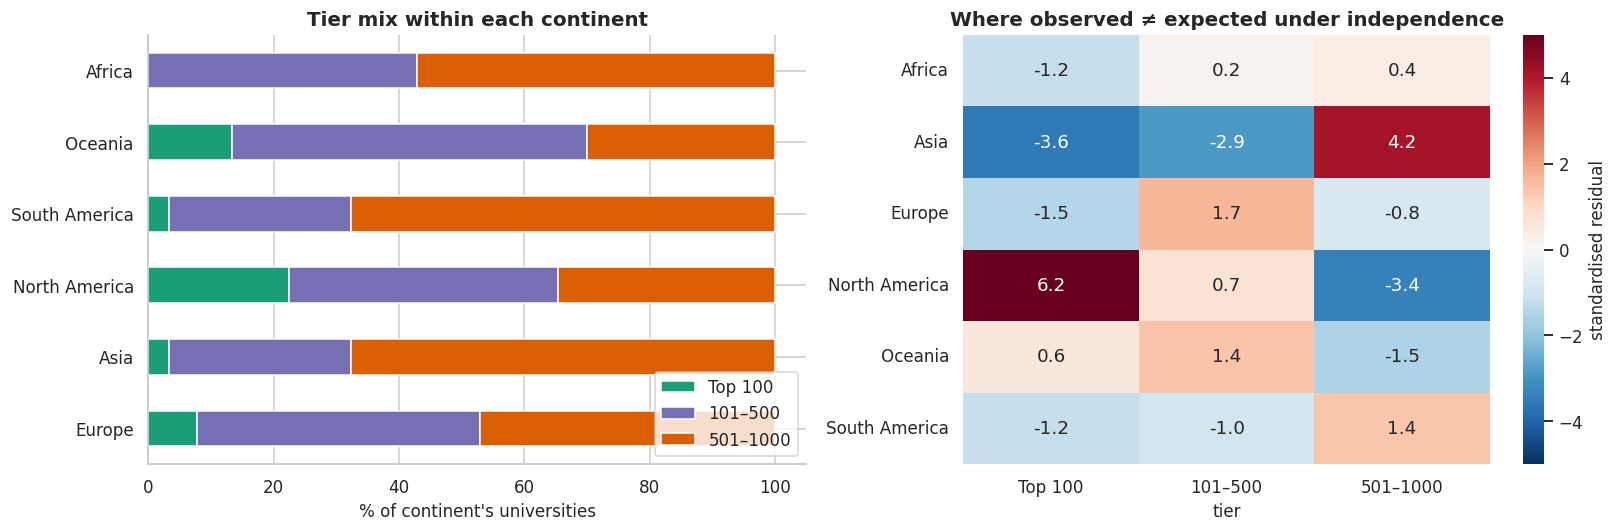


χ²(10) = **104.4**, p = **6.99e-18** (Monte-Carlo p = 0.0002) → **reject H₀**. Cramér’s V = **0.23**.
Smallest expected cell count = 1.4 (⚠ below 5 – rely on the Monte-Carlo p-value).


In [24]:
ct = pd.crosstab(sub.continent, sub.tier)[TIER_ORDER]
chi2, p_chi, dof, exp = stats.chi2_contingency(ct)
V = cramers_v(ct)
std_res = (ct - exp) / np.sqrt(exp)

# Monte-Carlo p-value (robust to sparse cells)
ci_codes = pd.factorize(sub.continent)[0]; ti_codes = sub.tier.astype(str).map({t: i for i, t in enumerate(TIER_ORDER)}).values.astype(int)
nc = ci_codes.max() + 1
def chi_stat(tc):
    obsm = np.bincount(ci_codes * 3 + tc, minlength=nc * 3).reshape(nc, 3).astype(float)
    e = obsm.sum(1, keepdims=True) * obsm.sum(0, keepdims=True) / obsm.sum()
    return np.sum((obsm - e) ** 2 / e)
obs_chi = chi_stat(ti_codes)
mc = np.array([chi_stat(rng.permutation(ti_codes)) for _ in range(5000)])
p_mc = (np.sum(mc >= obs_chi) + 1) / 5001
register("H3 continent × tier", "χ² independence", chi2, p_chi, "Cramér's V", V, len(sub))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
(ct.div(ct.sum(axis=1), axis=0) * 100).loc[ct.sum(axis=1).sort_values(ascending=False).index].plot.barh(stacked=True, ax=axes[0], color=[TIER_PAL[t] for t in TIER_ORDER])
axes[0].set(title="Tier mix within each continent", xlabel="% of continent's universities", ylabel=""); axes[0].legend(title=None, loc="lower right")
sns.heatmap(std_res, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-5, vmax=5, ax=axes[1], cbar_kws={"label": "standardised residual"})
axes[1].set(title="Where observed ≠ expected under independence", ylabel="")
plt.tight_layout(); plt.show(); save(fig, "18_chi_square")

md(f"""
χ²({dof}) = **{chi2:.1f}**, p = **{p_chi:.3g}** (Monte-Carlo p = {p_mc:.4f}) → **{verdict(p_chi)}**. Cramér’s V = **{V:.2f}**.
Smallest expected cell count = {exp.min():.1f} ({'⚠ below 5 – rely on the Monte-Carlo p-value' if exp.min()<5 else 'all ≥ 5, asymptotic test is valid'}).
""")

### H4 · Which indicators move with the score? (correlation inference)
* **H₀:** Spearman ρ = 0 for each indicator.  **H₁:** ρ ≠ 0.
* **Approach:** report ρ with **bootstrap 95% CIs** (no normality assumption), apply **Holm correction** across the five tests, and run a **sensitivity analysis** excluding right-censored (“> 1000”) values – if ρ barely changes, the `1001` convention is harmless.

,ρ,CI low,CI high,p_raw,ρ excl. censored,n excl. censored,p_holm
indicator,,,,,,,
Alumni Employment,0.437,0.378,0.491,0.000,0.370,491,0.000
Research Output,0.888,0.873,0.902,0.000,0.886,923,0.000
Quality Publications,0.955,0.947,0.963,0.000,0.959,949,0.000
Influence,0.885,0.869,0.899,0.000,0.895,829,0.000
Citations,0.851,0.830,0.869,0.000,0.854,890,0.000


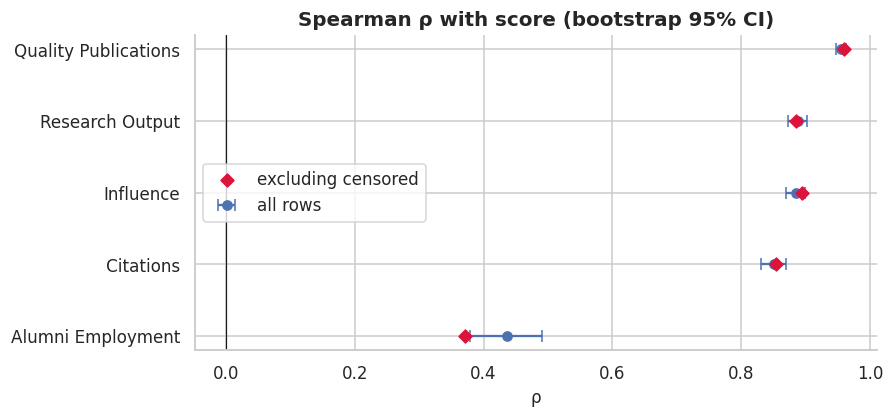

In [25]:
def spearman_boot(x, y, B=2000):
    n = len(x); idx = rng.integers(0, n, (B, n)); rx, ry = stats.rankdata(x), stats.rankdata(y)
    out = np.empty(B)
    for i in range(B):
        out[i] = np.corrcoef(rx[idx[i]], ry[idx[i]])[0, 1]     # Spearman computed on the original ranks, resampled
    return np.quantile(out, [.025, .975])

rows = []
for c in CORE:
    rho, p = stats.spearmanr(df[f"{c}_str"], df.score)
    lo, hi = spearman_boot(df[f"{c}_str"].values, df.score.values)
    ok = ~df[f"{c}_censored"]
    rho_nc, _ = stats.spearmanr(df.loc[ok, f"{c}_str"], df.loc[ok, "score"])
    rows.append({"indicator": IND_LABEL[c], "ρ": rho, "CI low": lo, "CI high": hi, "p_raw": p,
                 "ρ excl. censored": rho_nc, "n excl. censored": int(ok.sum())})
cor = pd.DataFrame(rows).set_index("indicator")
cor["p_holm"] = multipletests(cor.p_raw, method="holm")[1]
for c, (_, r) in zip(CORE, cor.iterrows()): register(f"H4 ρ(score, {c})", "Spearman", r["ρ"], r["p_raw"], "ρ", r["ρ"], len(df))
display(cor)

fig, ax = plt.subplots(figsize=(8, 3.8)); cs = cor.sort_values("ρ")
ax.errorbar(cs["ρ"], range(len(cs)), xerr=[cs["ρ"] - cs["CI low"], cs["CI high"] - cs["ρ"]], fmt="o", capsize=4, color="#4c72b0", label="all rows")
ax.scatter(cs["ρ excl. censored"], range(len(cs)), marker="D", color="crimson", zorder=5, label="excluding censored")
ax.set_yticks(range(len(cs))); ax.set_yticklabels(cs.index); ax.axvline(0, color="k", lw=.8)
ax.set(title="Spearman ρ with score (bootstrap 95% CI)", xlabel="ρ"); ax.legend(loc="center left")
plt.show(); save(fig, "19_correlation_forest")

**Interpretation.** Every indicator is significantly related to the score (they *construct* it), so the p-values are uninformative – what matters is the **ordering and size of ρ** and the fact that the red diamonds (censored rows removed) sit close to the blue estimates, showing the censoring convention does not drive the conclusions. Recall these are descriptive associations, not independent evidence of “importance”: the score is built from these inputs.

### H5 · Probability analysis – how likely is an institution to reach the Top 100?
A frequentist proportion is unstable for small groups (a country with 3 universities and 1 in the Top 100 is *not* “33% elite”). A **Bayesian Beta–Binomial model** gives a full posterior for each country’s Top-100 rate and lets us ask direct questions such as *“what is the probability that country A’s rate exceeds country B’s?”*

* Prior: **Beta(1, 1)** (uniform) · Likelihood: Binomial(n, θ) · Posterior: **Beta(1 + k, 1 + n − k)**, k = number of Top-100 universities, n = universities in the country.

,n,k (Top 100),MLE k/n,posterior mean,95% credible lo,95% credible hi
USA,213.000,51.000,0.239,0.242,0.187,0.301
China,108.000,2.000,0.019,0.027,0.006,0.065
United Kingdom,62.000,8.000,0.129,0.141,0.067,0.235
France,58.000,4.000,0.069,0.083,0.028,0.165
Japan,56.000,3.000,0.054,0.069,0.019,0.146
Germany,54.000,3.000,0.056,0.071,0.020,0.151


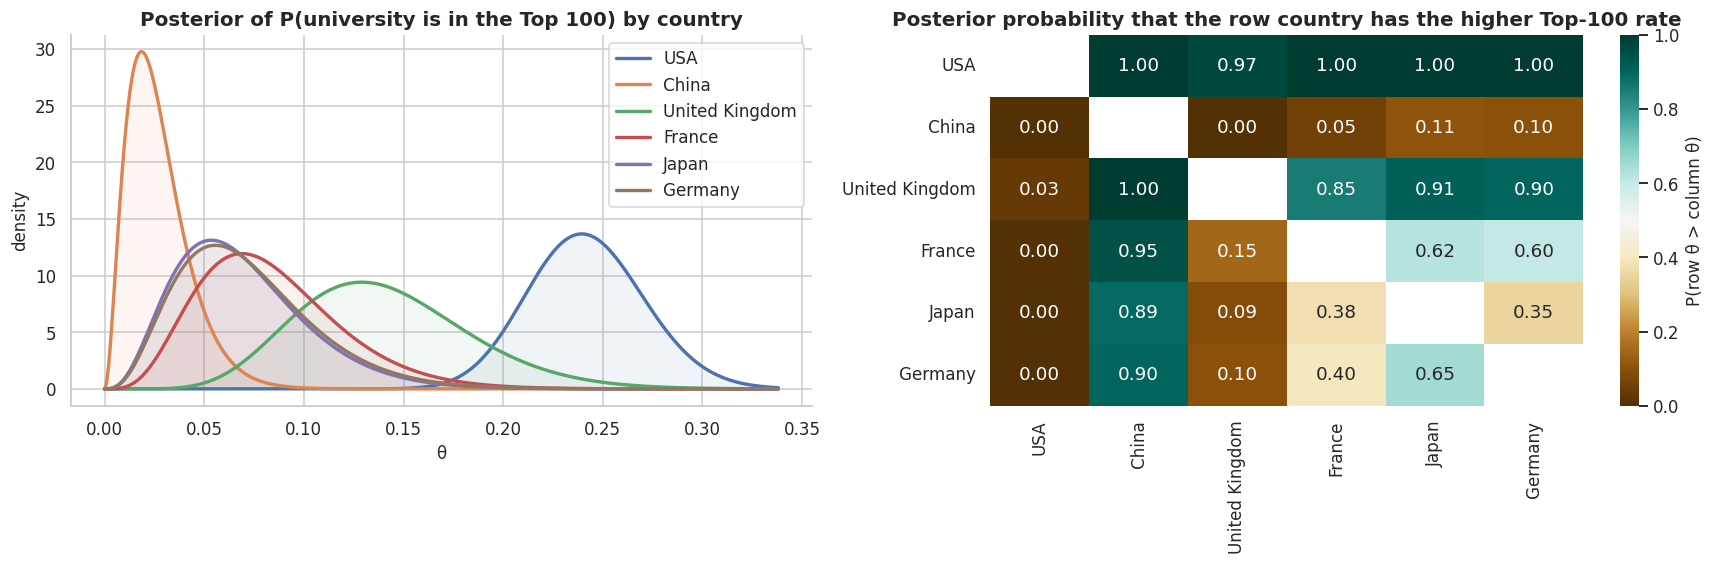

**Bayes’ theorem sanity check.** P(Top 100 | USA) = **23.9%**, but P(USA | Top 100) = **51.0%** – the two are different questions: the second is large because USA is *both* big and strong, the first measures strength alone. Confusing them is the classic *prosecutor’s fallacy*.

In [26]:
big6 = cnt.head(6).index.tolist()
post_b = {}
for c in big6:
    n_c = int((df.country == c).sum()); k_c = int(df.loc[df.country == c, "top100"].sum())
    post_b[c] = stats.beta(1 + k_c, 1 + n_c - k_c)
tab = pd.DataFrame({c: {"n": int((df.country == c).sum()), "k (Top 100)": int(df.loc[df.country == c, "top100"].sum()),
                        "MLE k/n": df.loc[df.country == c, "top100"].mean(), "posterior mean": d.mean(),
                        "95% credible lo": d.ppf(.025), "95% credible hi": d.ppf(.975)} for c, d in post_b.items()}).T
display(tab)

S = 100_000; draws = {c: d.rvs(S, random_state=SEED) for c, d in post_b.items()}
Pm = pd.DataFrame({b: {a: np.mean(draws[a] > draws[b]) if a != b else np.nan for a in big6} for b in big6})

fig, axes = plt.subplots(1, 2, figsize=(16, 5.3))
xs = np.linspace(0, max(d.ppf(.999) for d in post_b.values()), 500)
for c, d in post_b.items():
    axes[0].plot(xs, d.pdf(xs), lw=2.2, label=c); axes[0].fill_between(xs, d.pdf(xs), alpha=.08)
axes[0].set(title="Posterior of P(university is in the Top 100) by country", xlabel="θ", ylabel="density"); axes[0].legend()
sns.heatmap(Pm.astype(float), annot=True, fmt=".2f", cmap="BrBG", center=.5, vmin=0, vmax=1, ax=axes[1], cbar_kws={"label": "P(row θ > column θ)"})
axes[1].set_title("Posterior probability that the row country has the higher Top-100 rate")
plt.tight_layout(); plt.show(); save(fig, "20_bayesian_top100")

# Bayes' theorem in words: P(country | Top 100) vs P(Top 100 | country)
c0 = big6[0]
p_t_given_c = df.loc[df.country == c0, "top100"].mean(); p_c_given_t = (df.loc[df.top100 == 1, "country"] == c0).mean()
md(f"**Bayes’ theorem sanity check.** P(Top 100 | {c0}) = **{p_t_given_c:.1%}**, but P({c0} | Top 100) = **{p_c_given_t:.1%}** – "
   f"the two are different questions: the second is large because {c0} is *both* big and strong, the first measures strength alone. "
   f"Confusing them is the classic *prosecutor’s fallacy*.")

### Multiple-testing correction & summary of all tests
Running many tests inflates the chance of at least one false positive. We apply **Holm** (controls family-wise error rate) and **Benjamini–Hochberg** (controls false-discovery rate) across the whole registry.

In [27]:
reg = pd.DataFrame(REGISTRY)
reg["p_holm"] = multipletests(reg.p_value, method="holm")[1]
reg["p_BH(FDR)"] = multipletests(reg.p_value, method="fdr_bh")[1]
reg["significant (Holm)"] = np.where(reg.p_holm < ALPHA, "yes", "no")
display(reg.set_index("hypothesis")[["test", "n", "statistic", "p_value", "p_holm", "p_BH(FDR)", "effect_size", "effect", "significant (Holm)"]])

,test,n,statistic,p_value,p_holm,p_BH(FDR),effect_size,effect,significant (Holm)
hypothesis,,,,,,,,,
H1 continents differ in score,Kruskal–Wallis,1000,99.869,0.000,0.000,0.000,ε²,0.100,yes
H2 USA vs rest,Mann–Whitney U,1000,"108,617.500",0.000,0.000,0.000,Cliff's δ,0.296,yes
H3 continent × tier,χ² independence,1000,104.449,0.000,0.000,0.000,Cramér's V,0.229,yes
"H4 ρ(score, alumni)",Spearman,1000,0.437,0.000,0.000,0.000,ρ,0.437,yes
"H4 ρ(score, research_output)",Spearman,1000,0.888,0.000,0.000,0.000,ρ,0.888,yes
"H4 ρ(score, quality_pubs)",Spearman,1000,0.955,0.000,0.000,0.000,ρ,0.955,yes
"H4 ρ(score, influence)",Spearman,1000,0.885,0.000,0.000,0.000,ρ,0.885,yes
"H4 ρ(score, citations)",Spearman,1000,0.851,0.000,0.000,0.000,ρ,0.851,yes


<a class="anchor" id="regression"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">Explaining the Score: Regression and Diagnostics</p>

CWUR publishes a weighted formula, so a regression of `score` on the indicators is an *explanatory* exercise, not a forecast: it asks **how much of the score the fully-observed indicators account for, and which ones carry the most information**. Two caveats shape the setup:

* Quality of Education and Faculty (large weights in the real formula) are missing for 60–73 % of universities, so the main model can only use the **five fully-observed indicators**.
* The LOWESS plots in [How the Indicators Move Together](#relationships) showed the score is a **convex** function of indicator strength (it rises steeply near the top). We therefore compare four functional forms (linear / log score × raw strength / log-rank) and keep the best, using **heteroscedasticity-robust (HC3) standard errors**.

As a check on the “score is a formula” interpretation, the winning form is refitted with **all seven indicators** on the (rank-biased) subset where they are all observed.

In [28]:
for c in IND:                                   # "log-strength": higher = better, compresses the long tail of ranks
    df[f"{c}_lr"] = -np.log(df[c])
SPECS = {  # name -> (target, predictor suffix)
    "score ~ strength (linear)":     ("score", "_str"),
    "log(score) ~ strength":         ("log_score", "_str"),
    "score ~ −log(rank)":            ("score", "_lr"),
    "log(score) ~ −log(rank)":       ("log_score", "_lr"),
}
fits = {k: smf.ols(f"{y} ~ " + " + ".join(f"{c}{sfx}" for c in CORE), data=df).fit(cov_type="HC3") for k, (y, sfx) in SPECS.items()}
cmp_tbl = pd.DataFrame({k: {"n": int(f.nobs), "R²": f.rsquared, "adj. R²": f.rsquared_adj} for k, f in fits.items()}).T
display(cmp_tbl)

best_name = max(fits, key=lambda k: fits[k].rsquared)
ycol, sfx = SPECS[best_name]
X_cols = [f"{c}{sfx}" for c in CORE]
rhs = " + ".join(X_cols)
ols = fits[best_name]
r2_lin, r2_best = fits["score ~ strength (linear)"].rsquared, ols.rsquared

# the same functional form with ALL seven indicators, on the rows where Education & Faculty are observed (a rank-biased subset)
cc = df.dropna(subset=["edu", "faculty"])
fit_all = smf.ols(f"{ycol} ~ " + " + ".join(f"{c}{sfx}" for c in IND), data=cc).fit(cov_type="HC3")
fit_5cc = smf.ols(f"{ycol} ~ {rhs}", data=cc).fit(cov_type="HC3")
r2_all, r2_5cc = fit_all.rsquared, fit_5cc.rsquared
print(f"Best functional form: {best_name}\n")
print(ols.summary().tables[1])
md(f"The **{best_name}** specification fits best (R² = **{r2_best:.2f}**; plain linear model: {r2_lin:.2f})"
   + (" – the score is a *convex* function of the raw ranks, so a transformed form captures it better. " if best_name != "score ~ strength (linear)" else ". ")
   + f"On the {len(cc)} universities where all seven indicators are observed, the same form gives R² = {r2_5cc:.2f} with five indicators and **{r2_all:.2f}** with all seven. "
   + ("Adding Education and Faculty therefore **barely helps** – the unexplained part of the score is most likely due to information lost when raw measurements are converted to **ranks** (and censored at 1000), not to the two missing indicators."
      if r2_all - r2_5cc < .05 else
      "Adding Education and Faculty **improves the fit noticeably**, so part of the unexplained score is simply the missing indicators.")
   + " Either way this regression *describes how the published score relates to its inputs*; it is not a causal model.")

,n,R²,adj. R²
score ~ strength (linear),"1,000.000",0.848,0.848
log(score) ~ strength,"1,000.000",0.873,0.872
score ~ −log(rank),"1,000.000",0.954,0.954
log(score) ~ −log(rank),"1,000.000",0.945,0.944


Best functional form: score ~ −log(rank)

                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            104.6092      0.501    208.876      0.000     103.628     105.591
alumni_lr              0.4179      0.060      6.918      0.000       0.299       0.536
research_output_lr     0.9636      0.181      5.323      0.000       0.609       1.318
quality_pubs_lr        0.7028      0.319      2.204      0.028       0.078       1.328
influence_lr           2.1249      0.184     11.561      0.000       1.765       2.485
citations_lr           0.7532      0.111      6.786      0.000       0.536       0.971


The **score ~ −log(rank)** specification fits best (R² = **0.95**; plain linear model: 0.85) – the score is a *convex* function of the raw ranks, so a transformed form captures it better. On the 223 universities where all seven indicators are observed, the same form gives R² = 0.94 with five indicators and **0.95** with all seven. Adding Education and Faculty therefore **barely helps** – the unexplained part of the score is most likely due to information lost when raw measurements are converted to **ranks** (and censored at 1000), not to the two missing indicators. Either way this regression *describes how the published score relates to its inputs*; it is not a causal model.

,standardised β,ΔR² if dropped,VIF
Influence,0.461,0.022,9.524
Research Output,0.205,0.002,20.747
Citations,0.161,0.004,7.376
Quality Publications,0.149,0.001,43.230
Alumni Employment,0.090,0.006,1.267


**VIF** above ~5 signals multicollinearity: individual coefficients become unstable even though the overall fit stays good. Here max VIF = **43.2** (Quality Publications) → the research indicators overlap heavily, so read individual β with care; **ΔR² (what is lost when an indicator is removed) and the PCA view in Section 9 are safer guides to importance.**

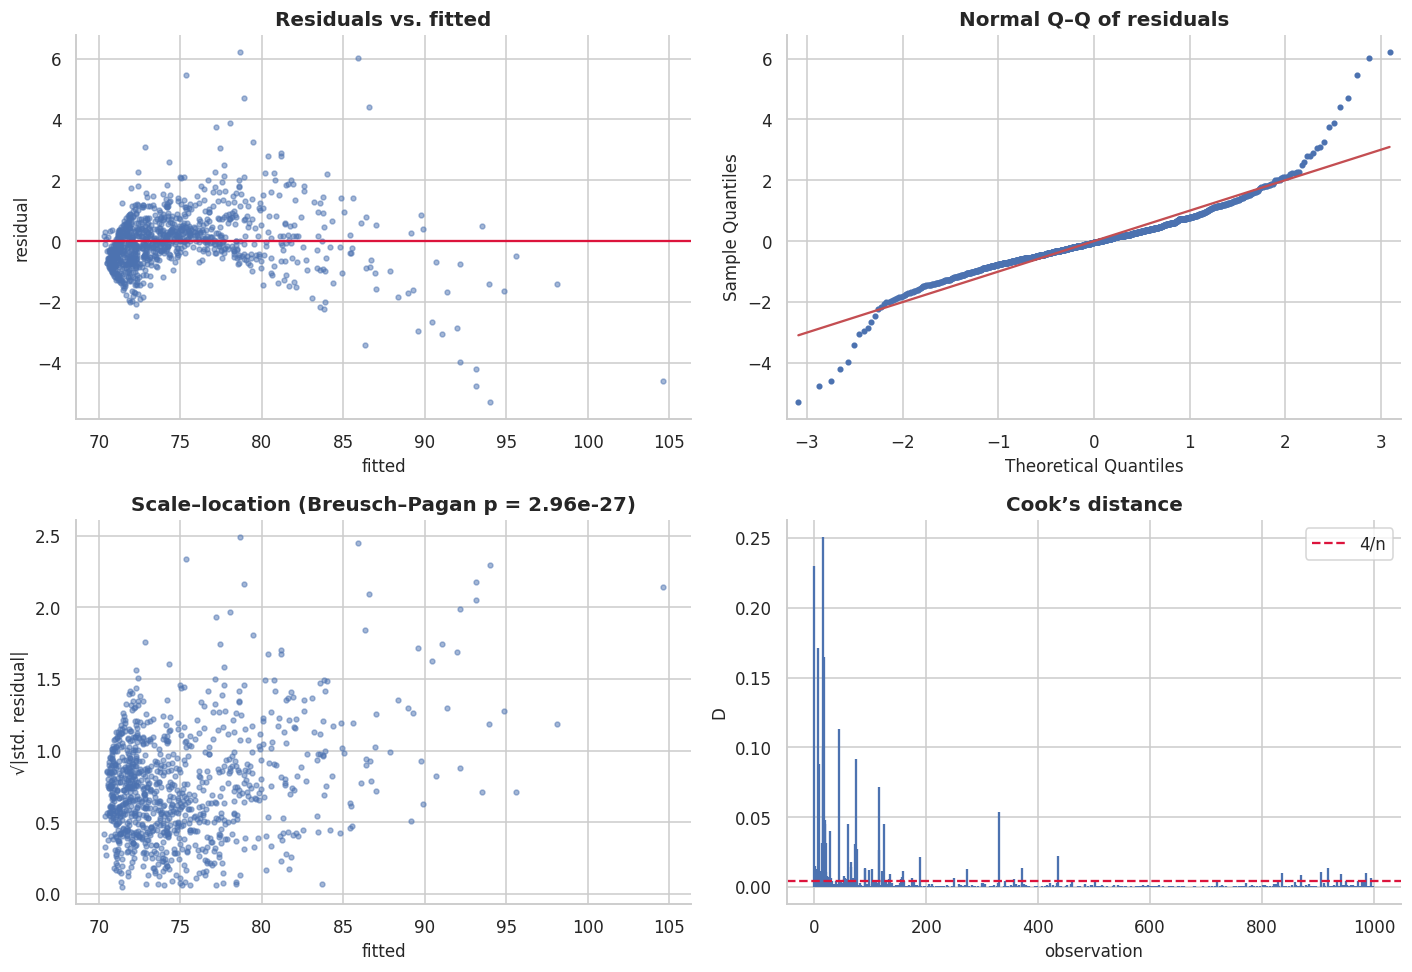

**Reading the diagnostics.** Breusch–Pagan p = 2.96e-27 → heteroscedasticity is present (hence the HC3 standard errors). A curved residual pattern or heavy-tailed Q–Q plot indicates the linear form is only an approximation – acceptable for *describing* relative importance, but a reason not to read coefficients as exact weights. 72 observations exceed the 4/n Cook’s-distance rule of thumb; the largest typically belong to the very top-ranked institutions, which is expected for a convex relationship and not a reason to drop them.

In [29]:
# Standardised coefficients, ΔR² when each predictor is dropped, and VIF
Z = df[[ycol] + X_cols].apply(stats.zscore)
std_fit = sm.OLS(Z[ycol], sm.add_constant(Z.drop(columns=ycol))).fit()
Xmat = sm.add_constant(df[X_cols])
imp = pd.DataFrame({
    "standardised β": std_fit.params.drop("const").values,
    "ΔR² if dropped": [ols.rsquared - smf.ols(f"{ycol} ~ " + " + ".join(k for k in X_cols if k != f"{c}{sfx}"), df).fit().rsquared for c in CORE],
    "VIF": [variance_inflation_factor(Xmat.values, i + 1) for i in range(len(CORE))],
}, index=[IND_LABEL[c] for c in CORE]).sort_values("standardised β", ascending=False)
display(imp)
md("**VIF** above ~5 signals multicollinearity: individual coefficients become unstable even though the overall fit stays good. "
   + f"Here max VIF = **{imp.VIF.max():.1f}** ({imp.VIF.idxmax()})"
   + (" → the research indicators overlap heavily, so read individual β with care; **ΔR² (what is lost when an indicator is removed) and the PCA view in Section 9 are safer guides to importance.**" if imp.VIF.max() > 5 else " → no serious collinearity."))

# diagnostics
infl = ols.get_influence(); fitted, resid = ols.fittedvalues, ols.resid; cook = infl.cooks_distance[0]
bp_p = het_breuschpagan(resid, Xmat)[1]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].scatter(fitted, resid, s=10, alpha=.5); axes[0, 0].axhline(0, color="crimson")
axes[0, 0].set(title="Residuals vs. fitted", xlabel="fitted", ylabel="residual")
sm.qqplot(resid, line="s", ax=axes[0, 1], markersize=3); axes[0, 1].set_title("Normal Q–Q of residuals")
axes[1, 0].scatter(fitted, np.sqrt(np.abs(stats.zscore(resid))), s=10, alpha=.5); axes[1, 0].set(title=f"Scale–location (Breusch–Pagan p = {bp_p:.3g})", xlabel="fitted", ylabel="√|std. residual|")
axes[1, 1].stem(np.arange(len(cook)), cook, markerfmt=" ", basefmt=" "); axes[1, 1].axhline(4 / len(cook), color="crimson", ls="--", label="4/n")
axes[1, 1].set(title="Cook’s distance", xlabel="observation", ylabel="D"); axes[1, 1].legend()
plt.tight_layout(); plt.show(); save(fig, "21_regression_diagnostics")
md(f"**Reading the diagnostics.** Breusch–Pagan p = {bp_p:.3g} → {'heteroscedasticity is present (hence the HC3 standard errors). ' if bp_p < ALPHA else 'no evidence of heteroscedasticity. '}"
   "A curved residual pattern or heavy-tailed Q–Q plot indicates the linear form is only an approximation – acceptable for *describing* relative importance, but a reason not to read coefficients as exact weights. "
   f"{int((cook > 4/len(cook)).sum())} observations exceed the 4/n Cook’s-distance rule of thumb; the largest typically belong to the very top-ranked institutions, which is expected for a convex relationship and not a reason to drop them.")

<a class="anchor" id="structure"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">The Hidden Structure of Excellence: PCA and Clustering</p>

Instead of using the published score, can the **raw indicator profiles** reveal natural groups of universities? Steps: standardise → **PCA** (summarise the indicators in fewer dimensions) → **K-Means** with k chosen by silhouette → profile the clusters and compare them with the official tiers (Adjusted Rand Index). These are used as *descriptive* tools – no prediction is involved.

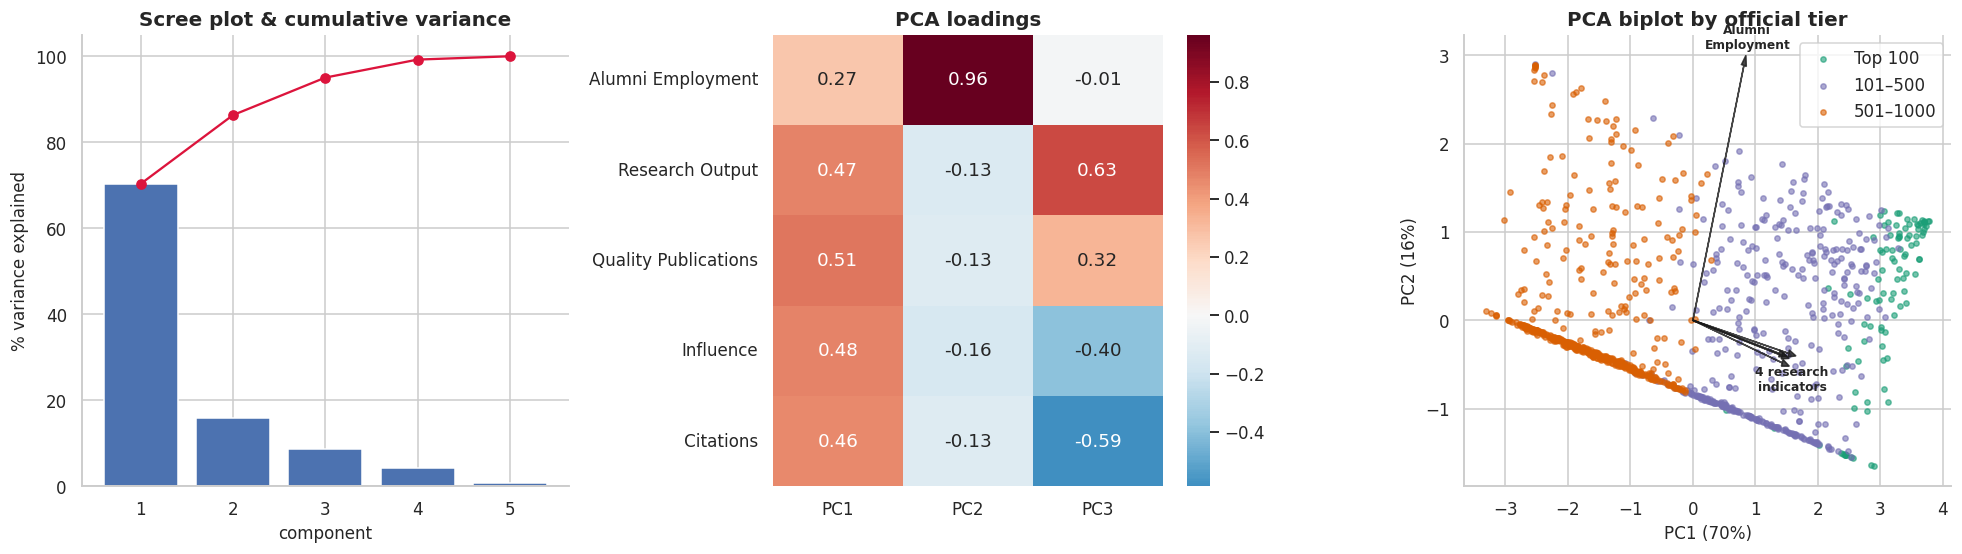

PC1 explains **70%** of variance and PC1+PC2 **86%**. PC1 loads on Quality Publications, Influence, Research Output – a general “overall strength” axis; PC2 contrasts the variables with opposite loading signs (see heatmap).

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

Xs = StandardScaler().fit_transform(df[[f"{c}_str" for c in CORE]])
pca = PCA().fit(Xs); scores_pca = pca.transform(Xs)
load = pd.DataFrame(pca.components_.T, index=[IND_LABEL[c] for c in CORE], columns=[f"PC{i+1}" for i in range(len(CORE))])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
ev = pca.explained_variance_ratio_
axes[0].bar(range(1, len(ev) + 1), ev * 100, color="#4c72b0"); axes[0].plot(range(1, len(ev) + 1), np.cumsum(ev) * 100, "o-", color="crimson")
axes[0].set(title="Scree plot & cumulative variance", xlabel="component", ylabel="% variance explained")
sns.heatmap(load.iloc[:, :3], annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1]); axes[1].set_title("PCA loadings")
for t in TIER_ORDER:
    m = df.tier == t; axes[2].scatter(scores_pca[m, 0], scores_pca[m, 1], s=12, alpha=.6, color=TIER_PAL[t], label=t)
for i, nme in enumerate(load.index):
    axes[2].arrow(0, 0, load.iloc[i, 0] * 3, load.iloc[i, 1] * 3, color="k", head_width=.08, alpha=.8)
axes[2].text(load.loc["Alumni Employment", "PC1"] * 3.2, load.loc["Alumni Employment", "PC2"] * 3.2, "Alumni\nEmployment", fontsize=8, fontweight="bold", ha="center")
rb = load.drop("Alumni Employment")
axes[2].text(rb.PC1.mean() * 3.3, rb.PC2.mean() * 3.3 - .35, "4 research\nindicators", fontsize=8, fontweight="bold", ha="center")
axes[2].set(title="PCA biplot by official tier", xlabel=f"PC1 ({ev[0]:.0%})", ylabel=f"PC2 ({ev[1]:.0%})"); axes[2].legend()
plt.tight_layout(); plt.show(); save(fig, "22_pca")
md(f"PC1 explains **{ev[0]:.0%}** of variance and PC1+PC2 **{ev[:2].sum():.0%}**. PC1 loads on {', '.join(load.PC1.abs().sort_values(ascending=False).index[:3])} – a general “overall strength” axis; PC2 contrasts the variables with opposite loading signs (see heatmap).")

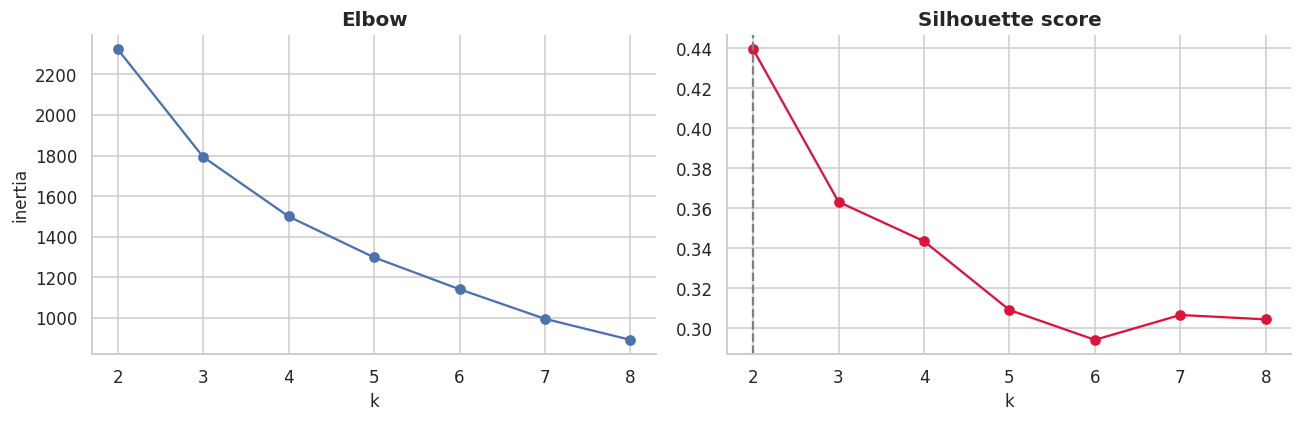

Silhouette selects **k = 2** (silhouette = 0.44). Agreement between clusters and official tiers: ARI = **0.71** (0 = random, 1 = identical). High agreement means the clusters largely recover the official tiers. Note that k = 2 is the *coarsest* possible structure (a stronger and a weaker half); the silhouette curve shows how quickly cohesion drops when more clusters are forced, i.e. the indicator profiles form a continuum rather than distinct types.

,Alumni Employment,Research Output,Quality Publications,Influence,Citations,Score,size
cluster,,,,,,,
C1,419.414,749.844,764.423,745.150,752.007,78.847,461
C2,150.505,272.482,270.126,238.089,284.167,71.773,539


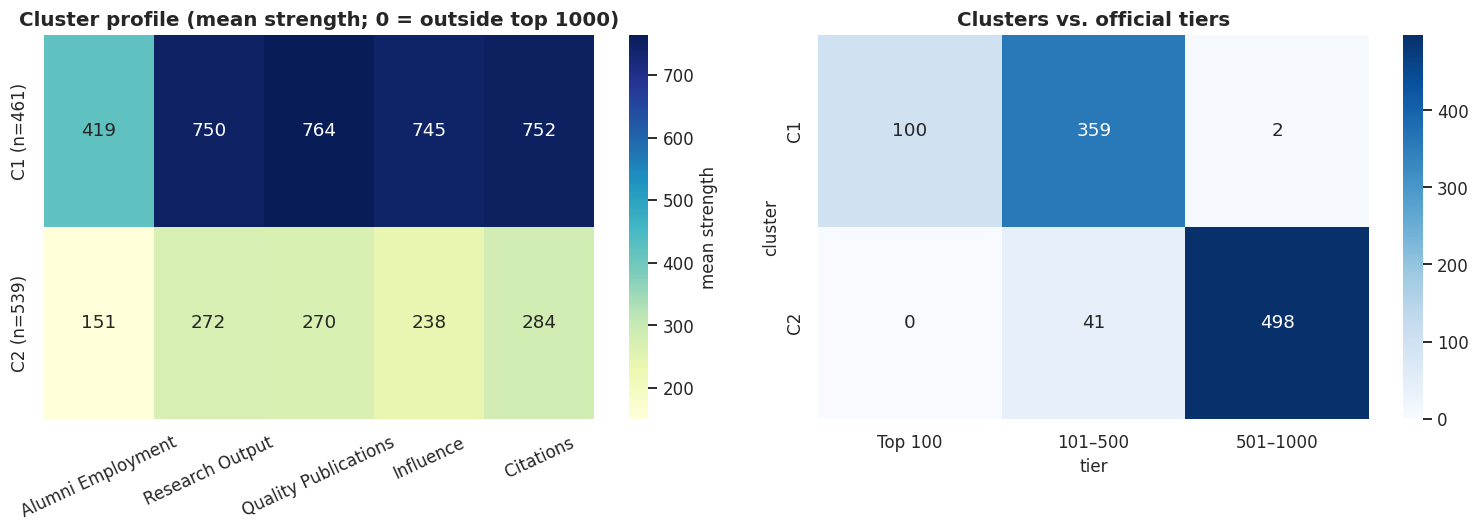

In [31]:
ks = range(2, 9); inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=SEED).fit(Xs); inertia.append(km.inertia_); sil.append(silhouette_score(Xs, km.labels_))
best_k = list(ks)[int(np.argmax(sil))]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertia, "o-"); axes[0].set(title="Elbow", xlabel="k", ylabel="inertia")
axes[1].plot(ks, sil, "o-", color="crimson"); axes[1].axvline(best_k, ls="--", color="grey"); axes[1].set(title="Silhouette score", xlabel="k")
plt.tight_layout(); plt.show(); save(fig, "23_kmeans_selection")

km = KMeans(best_k, n_init=20, random_state=SEED).fit(Xs)
# relabel clusters by mean score so labels are interpretable
rank_order = df.assign(c=km.labels_).groupby("c").score.mean().sort_values(ascending=False).index
df["cluster"] = pd.Series(km.labels_).map({old: f"C{i+1}" for i, old in enumerate(rank_order)}).values
ari = adjusted_rand_score(df.tier.astype(str), df.cluster)
md(f"Silhouette selects **k = {best_k}** (silhouette = {max(sil):.2f}). Agreement between clusters and official tiers: ARI = **{ari:.2f}** "
   f"(0 = random, 1 = identical). {'Moderate' if .2<ari<.6 else 'High' if ari>=.6 else 'Low'} agreement means the clusters {'largely recover' if ari>=.4 else 'cut across'} the official tiers. "
   "Note that k = 2 is the *coarsest* possible structure (a stronger and a weaker half); the silhouette curve shows how quickly cohesion drops when more clusters are forced, i.e. the indicator profiles form a continuum rather than distinct types.")

prof = df.groupby("cluster")[[f"{c}_str" for c in CORE] + ["score"]].mean().rename(columns=LAB)
prof["size"] = df.cluster.value_counts(); display(prof)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cprof = df.groupby("cluster")[[f"{c}_str" for c in CORE]].mean().rename(columns=LAB)
cprof.index = [f"{i} (n={n})" for i, n in zip(cprof.index, df.cluster.value_counts().reindex(cprof.index.str.split(" ").str[0]).values)]
sns.heatmap(cprof, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "mean strength"})
axes[0].set_title("Cluster profile (mean strength; 0 = outside top 1000)"); axes[0].tick_params(axis="x", rotation=25)
sns.heatmap(pd.crosstab(df.cluster, df.tier)[TIER_ORDER], annot=True, fmt="d", cmap="Blues", ax=axes[1]); axes[1].set_title("Clusters vs. official tiers")
plt.tight_layout(); plt.show(); save(fig, "24_clusters")

<a class="anchor" id="standouts"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">Who Stands Out? Reputation vs. Research</p>

**Why this needs care.** Alumni Employment is “> 1000” (outside the top 1000 on that indicator) for roughly half of all universities. Those values are *censored*, not equal to a rank of 1001, so any statistic that treats them as exact is misleading – especially a residual analysis. We therefore separate the question into two descriptive parts:

1. **Among universities whose alumni rank is observed** (top 1000 on that indicator): fit `alumni_str ~ research indicators` on those rows and list the largest **positive** residuals – employment standing far above what their research profile implies.
2. **Among universities whose alumni rank is censored:** list those with the **strongest research profile** – research powerhouses whose graduates do not reach the top 1000 on this indicator.

(Descriptive use of regression on the data we have – no train/test split, no forecasting.)

**51%** of universities have a censored alumni rank. Among the 491 with an observed rank, research indicators explain **R² = 0.07** of alumni-employment standing (a modest share – employment reputation is largely independent of research output).

**(1) Alumni employment far *stronger* than research implies** (observed alumni rank)

,institution,country,world_rank,alumni_rank,alumni_resid
0,INSEAD,France,436,2,582.889
1,École nationale d'administration,France,637,4,580.889
2,HEC Paris,France,589,6,578.889
3,China Europe International Business School,China,837,10,574.889
4,Indian Institute of Management Ahmedabad,India,919,14,570.889
5,Hitotsubashi University,Japan,907,16,568.889
6,Télécom ParisTech,France,942,47,568.470
7,University of St. Gallen,Switzerland,986,32,559.737
8,Stockholm School of Economics,Sweden,644,21,559.626
9,École des ponts ParisTech,France,780,26,558.889


**(2) Strongest research profiles whose alumni rank is outside the top 1000**

,institution,country,world_rank,research_strength
0,"University of California, San Diego",USA,20,984.750
1,"University of California, San Francisco",USA,22,977.750
2,Karolinska Institute,Sweden,49,932.500
3,Free University of Berlin,Germany,81,926.750
4,Humboldt University of Berlin,Germany,101,926.250
5,Grenoble Alpes University,France,97,915.000
6,Paris Diderot University,France,84,913.500
7,University of Helsinki,Finland,93,913.500
8,"University of California, Irvine",USA,59,913.250
9,Leiden University,Netherlands,90,911.750


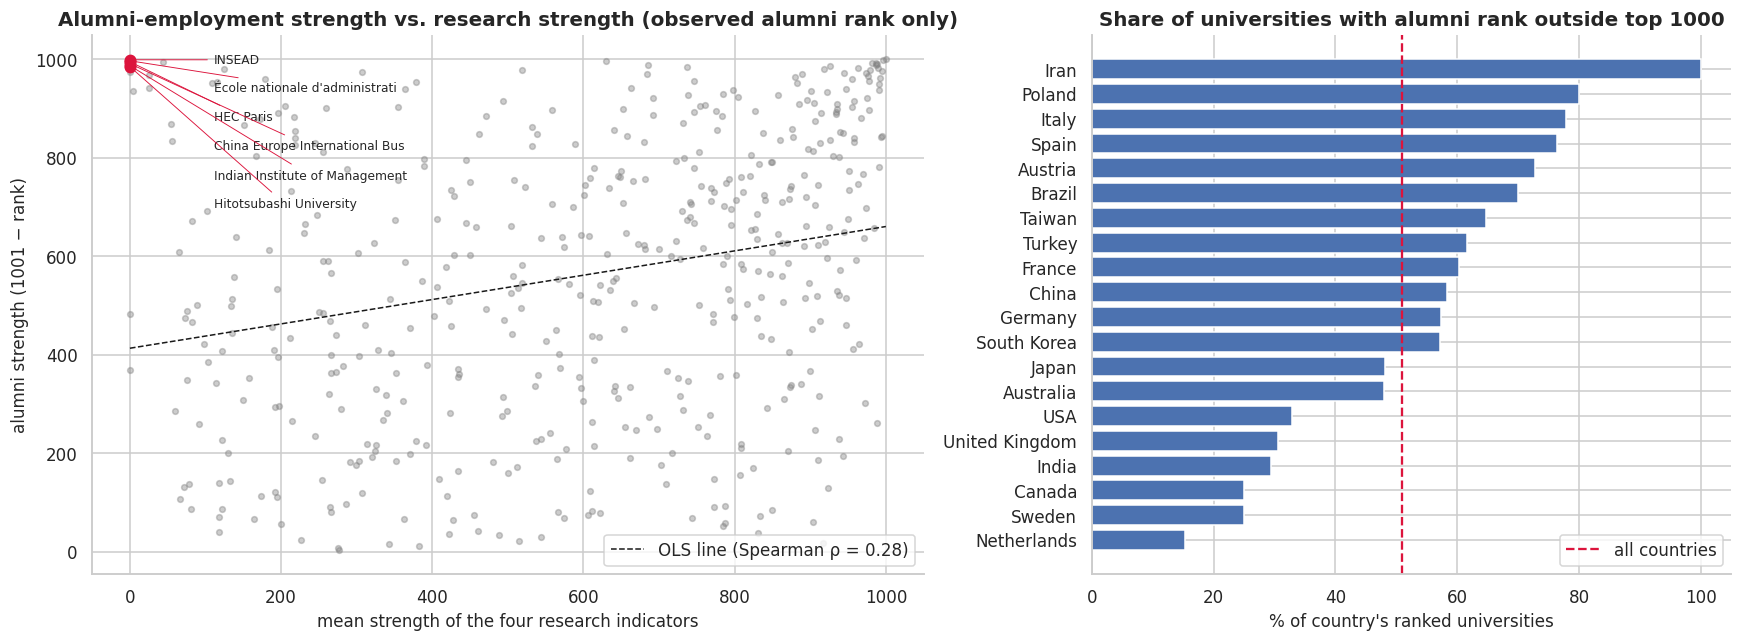

Is having an alumni rank outside the top 1000 related to continent? χ² = 46.6, p = 6.91e-09, Cramér’s V = 0.22 → **reject H₀**.

In [32]:
feat_res = [f"{c}_str" for c in RESEARCH]
unc = df[~df.alumni_censored].copy()
mod = smf.ols("alumni_str ~ " + " + ".join(feat_res), data=unc).fit(cov_type="HC3")
unc["alumni_resid"] = mod.resid
cen = df[df.alumni_censored].copy()
cen["research_strength"] = cen[feat_res].mean(axis=1)
share_cen = df.alumni_censored.mean()

md(f"**{share_cen:.0%}** of universities have a censored alumni rank. Among the {len(unc)} with an observed rank, research indicators explain **R² = {mod.rsquared:.2f}** of alumni-employment standing "
   f"({'a modest share – employment reputation is largely independent of research output' if mod.rsquared < .4 else 'a substantial share'}).")
cols = ["institution", "country", "world_rank", "alumni", "alumni_resid"]
display(Markdown("**(1) Alumni employment far *stronger* than research implies** (observed alumni rank)"))
display(unc.nlargest(10, "alumni_resid")[cols].rename(columns={"alumni": "alumni_rank"}).reset_index(drop=True))
display(Markdown("**(2) Strongest research profiles whose alumni rank is outside the top 1000**"))
display(cen.nlargest(10, "research_strength")[["institution", "country", "world_rank", "research_strength"]].reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.3, 1]})
unc["research_strength"] = unc[feat_res].mean(axis=1)
axes[0].scatter(unc.research_strength, unc.alumni_str, s=14, alpha=.4, color="grey")
slope, icpt = np.polyfit(unc.research_strength, unc.alumni_str, 1); xx = np.array([unc.research_strength.min(), unc.research_strength.max()])
rho_u, _ = stats.spearmanr(unc.research_strength, unc.alumni_str)
axes[0].plot(xx, icpt + slope * xx, "k--", lw=1, label=f"OLS line (Spearman ρ = {rho_u:.2f})")
for k, (_, r) in enumerate(unc.nlargest(6, "alumni_resid").iterrows()):
    axes[0].scatter(r.research_strength, r.alumni_str, s=45, color="crimson", zorder=5)
    axes[0].annotate(r.institution[:30], (r.research_strength, r.alumni_str), fontsize=8, xytext=(55, -18 * k),
                     textcoords="offset points", va="center", arrowprops=dict(arrowstyle="-", lw=.6, color="crimson"))
axes[0].set(title="Alumni-employment strength vs. research strength (observed alumni rank only)", xlabel="mean strength of the four research indicators", ylabel="alumni strength (1001 − rank)")
axes[0].legend(loc="lower right")
by_c = df[df.country.isin(cnt[cnt >= 10].index)].groupby("country").alumni_censored.mean().sort_values() * 100
axes[1].barh(by_c.index, by_c.values, color="#4c72b0"); axes[1].axvline(share_cen * 100, color="crimson", ls="--", label="all countries")
axes[1].set(title="Share of universities with alumni rank outside top 1000", xlabel="% of country's ranked universities"); axes[1].legend()
plt.tight_layout(); plt.show(); save(fig, "25_standouts")

# is the censoring share related to continent? (chi-square on a 2 × k table)
ct2 = pd.crosstab(df[df.continent.isin(big_cont)].continent, df[df.continent.isin(big_cont)].alumni_censored)
chi_c, p_c, _, _ = stats.chi2_contingency(ct2); V_c = cramers_v(ct2)
md(f"Is having an alumni rank outside the top 1000 related to continent? χ² = {chi_c:.1f}, p = {p_c:.3g}, Cramér’s V = {V_c:.2f} → **{verdict(p_c)}**.")

<a class="anchor" id="conclusions"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">What We Found: Conclusions, Limits and Next Steps</p>

The numbers in the table below are **generated from the executed analysis above**, so the narrative can never drift from the results.

In [33]:
top_cont = sub.groupby("continent").score.median().sort_values(ascending=False)
summary = f"""
### Key findings
1. **Data quality matters.** The original `isnull()` audit reported 0 missing values, but `"-"` and `"> 1000"` placeholders hid {df.edu.isna().mean():.0%} (education) / {df.faculty.isna().mean():.0%} (faculty) missingness plus right-censoring in the rank indicators – **{df.alumni_censored.mean():.0%} of Alumni Employment values are censored**. Missingness is {'related to rank (non-random)' if stats.mannwhitneyu(df.loc[df.edu.isna(),'world_rank'].astype(float), df.loc[df.edu.notna(),'world_rank'].astype(float)).pvalue < ALPHA else 'not clearly related to rank'}.
2. **Scores are right-skewed and non-normal** → rank-based inference was used throughout; best-fitting family by AIC: *{fit_tbl.index[0]}*.
3. **Concentration.** The top-5 countries hold {share.head(5).sum():.0%} of the 1000 universities (Gini = {gini(cnt):.2f}); **{TOP_C}** alone holds {share.iloc[0]:.0%} and {rep.loc[TOP_C,'share_top100']:.0%} of the Top 100.
4. **Geography: statistically clear differences – {"medium" if eps2 > .08 else "small"} across continents (ε²), {magnitude(delta)} for {TOP_C} vs. the rest (δ).** Kruskal–Wallis across continents: H = {H:.1f}, p = {p_kw:.2g}, ε² = {eps2:.3f}. {TOP_C} vs. the rest: Cliff’s δ = {delta:.2f} ({magnitude(delta)}), P(random {TOP_C} university outscores a foreign one) = {cles:.0%}; permutation and bootstrap agree.
5. **Tier is associated with continent** (χ² p = {p_chi:.2g}, Cramér’s V = {V:.2f}). Bayesian posterior P(Top 100) for {big6[0]} = {post_b[big6[0]].mean():.1%} [{post_b[big6[0]].ppf(.025):.1%}, {post_b[big6[0]].ppf(.975):.1%}].
6. **Indicator structure.** Research indicators form a highly correlated block (max VIF = {imp.VIF.max():.1f}); strongest rank-correlate of the score: **{cor['ρ'].idxmax()}** (ρ = {cor['ρ'].max():.2f}), weakest: **{cor['ρ'].idxmin()}** (ρ = {cor['ρ'].min():.2f}). The five fully-observed indicators explain R² = {r2_lin:.2f} of the score linearly and **{r2_best:.2f}** with the best functional form ({best_name}); using all seven indicators (complete cases) gives R² = {r2_all:.2f} vs. {r2_5cc:.2f} with five.
7. **Structure:** PC1 captures {ev[0]:.0%} of indicator variance (an “overall strength” axis); K-Means (descriptive) finds k = {best_k} clusters (silhouette {max(sil):.2f}), ARI = {ari:.2f} against the official tiers.
8. **Standouts:** among universities with an observed alumni rank, research explains R² = {mod.rsquared:.2f} of alumni standing; the largest positive residual is **{unc.nlargest(1,'alumni_resid').institution.iloc[0]}**. Strongest research profile with alumni rank outside the top 1000: **{cen.nlargest(1,'research_strength').institution.iloc[0]}**.
"""
md(summary)


### Key findings
1. **Data quality matters.** The original `isnull()` audit reported 0 missing values, but `"-"` and `"> 1000"` placeholders hid 60% (education) / 73% (faculty) missingness plus right-censoring in the rank indicators – **51% of Alumni Employment values are censored**. Missingness is related to rank (non-random).
2. **Scores are right-skewed and non-normal** → rank-based inference was used throughout; best-fitting family by AIC: *Weibull*.
3. **Concentration.** The top-5 countries hold 50% of the 1000 universities (Gini = 0.69); **USA** alone holds 21% and 51% of the Top 100.
4. **Geography: statistically clear differences – medium across continents (ε²), small for USA vs. the rest (δ).** Kruskal–Wallis across continents: H = 99.9, p = 5.6e-20, ε² = 0.100. USA vs. the rest: Cliff’s δ = 0.30 (small), P(random USA university outscores a foreign one) = 65%; permutation and bootstrap agree.
5. **Tier is associated with continent** (χ² p = 7e-18, Cramér’s V = 0.23). Bayesian posterior P(Top 100) for USA = 24.2% [18.7%, 30.1%].
6. **Indicator structure.** Research indicators form a highly correlated block (max VIF = 43.2); strongest rank-correlate of the score: **Quality Publications** (ρ = 0.96), weakest: **Alumni Employment** (ρ = 0.44). The five fully-observed indicators explain R² = 0.85 of the score linearly and **0.95** with the best functional form (score ~ −log(rank)); using all seven indicators (complete cases) gives R² = 0.95 vs. 0.94 with five.
7. **Structure:** PC1 captures 70% of indicator variance (an “overall strength” axis); K-Means (descriptive) finds k = 2 clusters (silhouette 0.44), ARI = 0.71 against the official tiers.
8. **Standouts:** among universities with an observed alumni rank, research explains R² = 0.07 of alumni standing; the largest positive residual is **INSEAD**. Strongest research profile with alumni rank outside the top 1000: **University of California, San Diego**.


### Limitations (read before citing any number)
* **Single snapshot (CWUR 2018–19)** – no time dimension, so no claims about *change*.
* **Circularity:** the score is a weighted function of the indicators; correlations and regression coefficients describe the **formula**, not causal drivers of excellence.
* **Ordinal ranks, not raw measurements** – indicators are ranks (and right-censored at 1000), which discard magnitude; strengths = 1001 − rank are a convenience transform.
* **Selection bias** – only the top 1000 institutions are published; conclusions do not generalise to all universities.
* **Confounders not in the data** – country population, GDP, R&D spending, language and institution age/size are unobserved, so geographic differences are **associations, not causal effects**.
* **Ecological inference** – country/continent-level patterns do not describe individual institutions.
* **Multiple testing** – addressed with Holm/BH, but exploratory comparisons (e.g. over/under-performers) should be treated as hypothesis-generating.

### Recommendations & next steps
1. **Add context data** (World Bank GDP, R&D % of GDP, population) → test whether the geographic gap shrinks after adjustment (multiple regression / mixed-effects model with country random intercepts).
2. **Use all CWUR editions (2012–2019)** to study rank *dynamics* (survival of Top-100 status, convergence/divergence between regions).
3. **Hierarchical Bayesian model** of Top-100 probability with partial pooling across countries – a principled upgrade to the independent Beta–Binomial estimates in H5.
4. **Sensitivity analysis** of the conclusions to the censoring convention and minimum-group-size thresholds.
5. **Ship it:** a small Streamlit dashboard showing country profiles and posterior Top-100 probabilities; wrap the pipeline in a script with tests and CI.

---
*Built with Python 3, pandas, NumPy, SciPy, statsmodels, scikit-learn, seaborn, matplotlib. Data: my Kaggle dataset of the CWUR 2018–19 ranking; the ranking methodology and underlying data originate from the Center for World University Rankings (CWUR).*